# 🎯 ETS Elektronika Cerdas — Object Detection (Indoor)

### Transfer Learning YOLO · Dataset *Indoor Object Detection* (Mendeley)

**Nama :** `Muhammad Zahran Razzaq` &nbsp;&nbsp;|&nbsp;&nbsp; **NRP :** `5024xxxxxx`
**Departemen Teknik Elektro — ITS Surabaya** · Dosen: **Prof. Djoko Purwanto**

---

Notebook ini adalah *starter kit* ETS yang **siap dijalankan 1 klik** (Runtime ▸ Run all).
Seluruh alur mengikuti materi kuliah *Object Detection* (39 slide):

| Tahap | Slide | Isi |
|---|---|---|
| 0 | — | Panel Kontrol Soal ETS (subset kelas / subset gambar) |
| 1 | — | Unduh dataset Mendeley 433 MB + ekstrak **nested ZIP** otomatis |
| 2 | 21, 30 | Konversi **Pascal VOC (.xml) → YOLO (.txt)** + struktur `datasets/{train,valid,test}/{images,labels}` |
| 3 | 21, 31 | **Class Distribution** & validasi dataset (5 kriteria dataset) |
| 4 | 25, 28, 31 | **Transfer learning** `yolo12n.pt` / `yolo11n.pt` → `MyYOLOModel.pt` |
| 5 | 26, 32, 33 | Evaluasi: **P, R, mAP50, mAP50-95** (total & per kelas) + `results.png` |
| 6 | 34, 35 | `confusion_matrix.png` + `val_batch0_labels.jpg` vs `val_batch0_pred.jpg` |
| 7 | 36 | Inferensi gambar: **Upload foto** & **Webcam browser** → `detection_result.jpg` |
| 8 | 3, 37, 38 | **Indoor Security Camera**: object counter, auto-save, auto-record `.mp4` |
| 9 | 25 | Ekspor **ONNX** (opsional) |
| 10 | — | Unduh **`Hasil_ETS_ObjectDetection.zip`** (1 klik) |

> ⚠️ **Sebelum dikumpulkan ke MyITS Classroom**: isi **Nama & NRP** di komentar baris awal setiap file `.py`
> (`scripts_lokal/*.py`), lalu kompres menjadi **`Nama_NRP.zip`**.

> 💡 **GPU gratis**: menu `Runtime ▸ Change runtime type ▸ T4 GPU`.
> Tanpa GPU, training tetap jalan di CPU tapi jauh lebih lambat.


---
## ⚙️ Panel Kontrol Soal ETS

**Cukup ubah sel di bawah ini** sebelum `Run all`. Semua nilai dipakai otomatis oleh sel-sel berikutnya.

| Variabel | Fungsi | Nilai umum |
|---|---|---|
| `SELECTED_CLASSES` | Jika dosen hanya meminta **sebagian kelas** | `None` (7 kelas) atau `['chair', 'door']` |
| `MAX_TRAIN_IMAGES` | Jika **waktu ujian mepet** → subset data | `None` (12.012 gambar) atau `2000` |
| `MAX_VALID_IMAGES` / `MAX_TEST_IMAGES` | Subset validasi/test | `None` (490 / 245) |
| `RESPLIT_70_15_15` | Buang split Roboflow 94/4/2 lalu split ulang 70/15/15 (Slide 21) | `False` / `True` |
| `MODEL_NAME` | Pre-trained sesuai slide | `yolo12n.pt` (Slide 28-31) / `yolo11n.pt` (Slide 25) |
| `EPOCHS`, `PATIENCE`, `IMGSZ`, `BATCH` | Hyperparameter `model.train(...)` | `60 / 15 / 640 / 16` |
| `EXPORT_ONNX` | Ekspor model ke ONNX (Slide 25) | `False` / `True` |

**Jebakan yang sudah ditangani otomatis** (jangan diubah kecuali paham):
1. Anotasi dataset masih **Pascal VOC `.xml`** → dikonversi ke YOLO `.txt` + di-*clamp* `[0,1]`.
2. Nama kelas **`fire extinguisher` memakai spasi** (bukan tanda hubung).
3. `data.yaml` memakai **`path` absolut** → menghindari bug Colab `/content/datasets/datasets/...`.
4. ZIP hasil "Download All" Mendeley masih **membungkus ZIP di dalam ZIP** → diekstrak bertingkat.


In [9]:
# =============================================================================
#  PANEL KONTROL SOAL ETS  —  ubah di sini saja
# =============================================================================
#  Nama : Muhammad Zahran Razzaq
#  NRP  : 5024xxxxxx
# =============================================================================

# ---------- 1. Soal: subset kelas ----------
#  None            -> semua 7 kelas:
#                     ['bin','chair','door','fire extinguisher','human','shelf','table']
#  ['chair','door'] -> hanya 2 kelas (nc=2), gambar tanpa kelas target dibuang
SELECTED_CLASSES = None

# ---------- 2. Soal: batas jumlah gambar (waktu ujian mepet) ----------
MAX_TRAIN_IMAGES = 2000      # None = semua 12.012 gambar; mis. 2000 untuk uji cepat
MAX_VALID_IMAGES = None      # None = semua 490
MAX_TEST_IMAGES  = None      # None = semua 245

# ---------- 3. Strategi split ----------
#  False -> pakai split asli dataset Roboflow (train 94% / valid 4% / test 2%). Cepat & aman.
#  True  -> gabung semua gambar lalu split ulang 70/15/15 sesuai Slide 21.
RESPLIT_70_15_15 = False

# ---------- 4. Model & hyperparameter (Slide 25 & 31) ----------
MODEL_NAME = "yolo12n.pt"    # "yolo12n.pt" (Slide 28-31) atau "yolo11n.pt" (Slide 25)
EPOCHS     = 30
PATIENCE   = 15              # early stopping
IMGSZ      = 640
BATCH      = 16
DEVICE     = 0               # 0 = GPU T4; otomatis jadi 'cpu' bila GPU tidak ada
WORKERS    = 2

# ---------- 5. Opsi tambahan ----------
EXPORT_ONNX   = False        # True -> MyYOLOModel.onnx (Slide 25)
FORCE_REDOWNLOAD = False     # True -> unduh ulang dataset dari Mendeley
USE_GOOGLE_DRIVE = False     # True -> pakai ZIP dari Google Drive (jalur lebih cepat)
DRIVE_ZIP_PATH   = "/content/drive/MyDrive/Indoor Objects.v1i.voc.zip"
SAVE_TO_DRIVE    = False     # True -> simpan MyYOLOModel.pt + hasil ke Google Drive

# ---------- Konstanta dataset (JANGAN diubah) ----------
CLASSES = ['bin', 'chair', 'door', 'fire extinguisher', 'human', 'shelf', 'table']
DATASET_URL = ("https://data.mendeley.com/public-files/datasets/3ggxwf2vpr/files/"
               "e9e913c0-e5eb-476b-a296-2ab55e55ada5/file_downloaded")
SPLITS = ["train", "valid", "test"]

AKTIF_KELAS = SELECTED_CLASSES if SELECTED_CLASSES else CLASSES
assert all(k in CLASSES for k in AKTIF_KELAS), f"Kelas tidak dikenal. Pilihan: {CLASSES}"

print("=" * 64)
print(" PANEL KONTROL SOAL ETS")
print("=" * 64)
print(f" Kelas dipakai    : {AKTIF_KELAS}   (nc = {len(AKTIF_KELAS)})")
print(f" Maks train/valid : {MAX_TRAIN_IMAGES} / {MAX_VALID_IMAGES} / {MAX_TEST_IMAGES}")
print(f" Split ulang 70/15/15: {RESPLIT_70_15_15}")
print(f" Model pre-trained: {MODEL_NAME}")
print(f" Training         : epochs={EPOCHS}, patience={PATIENCE}, imgsz={IMGSZ}, batch={BATCH}")
print("=" * 64)


 PANEL KONTROL SOAL ETS
 Kelas dipakai    : ['bin', 'chair', 'door', 'fire extinguisher', 'human', 'shelf', 'table']   (nc = 7)
 Maks train/valid : 2000 / None / None
 Split ulang 70/15/15: False
 Model pre-trained: yolo12n.pt
 Training         : epochs=30, patience=15, imgsz=640, batch=16


In [10]:
# =============================================================================
#  SETUP LINGKUNGAN — mount Drive (opsional), cek GPU, install Ultralytics
# =============================================================================
import os, sys, time, json, shutil, zipfile, random, subprocess, xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()

try:
    import ultralytics  # noqa: F401
    print("[=] ultralytics sudah terpasang")
except ImportError:
    print("[*] Meng-install ultralytics...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=False)

if USE_GOOGLE_DRIVE or SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        print("[OK] Google Drive ter-mount di /content/drive")
    except Exception as exc:
        print(f"[!] Gagal mount Drive: {exc}")

import torch
GPU_ADA = torch.cuda.is_available()
if GPU_ADA:
    DEVICE = 0
    print(f"[OK] GPU: {torch.cuda.get_device_name(0)} | "
          f"VRAM {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
else:
    DEVICE = "cpu"
    print("[!] GPU tidak terdeteksi -> DEVICE='cpu'. "
          "Aktifkan: Runtime > Change runtime type > T4 GPU")

import ultralytics
print(f"[OK] Torch {torch.__version__} | Ultralytics {ultralytics.__version__}")

# --- lokasi kerja ---
BASE       = Path("/content") if IN_COLAB else Path.cwd()
RAW_DIR    = BASE / "_raw"                       # ZIP + hasil ekstrak
DATASET_DIR= BASE / "datasets"                   # output YOLO (train/valid/test)
RUNS_DIR   = BASE / "runs"
OUT_DIR    = BASE / "ETS_results"                # artefak evaluasi
HASIL_DIR  = BASE / "hasil_inferensi"            # gambar/video hasil deteksi
DATA_YAML  = BASE / "data.yaml"
MODEL_FINAL= BASE / "MyYOLOModel.pt"

for d in (RAW_DIR, RUNS_DIR, OUT_DIR, HASIL_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"\n[i] BASE       = {BASE}")
print(f"[i] DATASET_DIR= {DATASET_DIR}")


[=] ultralytics sudah terpasang
[OK] GPU: Tesla T4 | VRAM 15.6 GB
[OK] Torch 2.11.0+cu130 | Ultralytics 8.4.189

[i] BASE       = /content
[i] DATASET_DIR= /content/datasets


In [11]:
# =============================================================================
#  TAHAP 1 — UNDUH DATASET MENDELEY + EKSTRAK NESTED ZIP
#  Halaman: https://data.mendeley.com/datasets/3ggxwf2vpr/1  (CC BY 4.0)
# =============================================================================

def ukuran_manusia(n: float) -> str:
    for satuan in ("B", "KB", "MB", "GB"):
        if n < 1024:
            return f"{n:.1f} {satuan}"
        n /= 1024
    return f"{n:.1f} TB"


def unduh(url: str, tujuan: Path) -> Path:
    '''Unduh dengan progress bar (requests -> fallback urllib).'''
    if tujuan.exists() and tujuan.stat().st_size > 50_000_000 and not FORCE_REDOWNLOAD:
        print(f"[=] Sudah ada, lewati unduh: {tujuan.name} ({ukuran_manusia(tujuan.stat().st_size)})")
        return tujuan
    tujuan.parent.mkdir(parents=True, exist_ok=True)
    print(f"[*] Mengunduh ~433 MB dari Mendeley...\n    {url}")
    t0 = time.time()
    try:
        import requests
        with requests.get(url, stream=True, timeout=180) as r:
            r.raise_for_status()
            total = int(r.headers.get("Content-Length", 0))
            sudah = 0
            with open(tujuan, "wb") as f:
                for potong in r.iter_content(chunk_size=2 * 1024 * 1024):
                    f.write(potong); sudah += len(potong)
                    if total:
                        persen = sudah / total * 100
                        print(f"\r    [{'#' * int(persen // 2):<50}] {persen:5.1f}% "
                              f"{ukuran_manusia(sudah)}/{ukuran_manusia(total)}",
                              end="", flush=True)
        print()
    except Exception as exc:
        print(f"[!] requests gagal ({exc}) -> mencoba urllib...")
        import urllib.request
        def _hook(blok, ukuran_blok, total):
            if total > 0:
                print(f"\r    {min(blok*ukuran_blok/total*100,100):5.1f}%", end="", flush=True)
        urllib.request.urlretrieve(url, tujuan, reporthook=_hook)
        print()
    print(f"[OK] Unduh selesai dalam {time.time()-t0:.1f} s -> "
          f"{tujuan.name} ({ukuran_manusia(tujuan.stat().st_size)})")
    return tujuan


def ekstrak_bertumpuk(zip_path: Path, tujuan: Path, maks_level: int = 3) -> None:
    '''Ekstrak ZIP; bila di dalamnya ada ZIP lagi (kasus "Download All" Mendeley), ekstrak ulang.'''
    tujuan.mkdir(parents=True, exist_ok=True)
    antre, sudah = [zip_path], set()
    for level in range(1, maks_level + 1):
        if not antre:
            break
        print(f"[*] Ekstrak level {level}: {len(antre)} arsip")
        berikutnya = []
        for z in antre:
            if z in sudah or not z.exists():
                continue
            sudah.add(z)
            print(f"    - {z.name} ({ukuran_manusia(z.stat().st_size)})")
            with zipfile.ZipFile(z) as zf:
                zf.extractall(tujuan)
                for nama in zf.namelist():
                    if nama.lower().endswith(".zip"):
                        kandidat = tujuan / nama
                        if kandidat.exists():
                            berikutnya.append(kandidat)
        antre = berikutnya
    print("[OK] Ekstraksi selesai")


def cari_root_dataset(folder: Path, kedalaman: int = 3) -> Path | None:
    '''Cari folder yang langsung berisi train/ dan valid/.'''
    kandidat = []
    for p in [folder, *folder.rglob("*")]:
        if p.is_dir() and len(p.relative_to(folder).parts) <= kedalaman:
            if (p / "train").is_dir() and (p / "valid").is_dir():
                kandidat.append(p)
    kandidat.sort(key=lambda p: len(p.parts))
    return kandidat[0] if kandidat else None


# ---------------------------------------------------------------- eksekusi
ROOT_DS = cari_root_dataset(RAW_DIR)
if ROOT_DS is not None:
    print(f"[=] Dataset sudah siap: {ROOT_DS}")
else:
    if USE_GOOGLE_DRIVE:
        src = Path(DRIVE_ZIP_PATH)
        if not src.exists():
            raise SystemExit(f"[X] ZIP Drive tidak ditemukan: {src}\n"
                             "    Unggah 'Indoor Objects.v1i.voc.zip' ke MyDrive dulu.")
        print(f"[*] Menyalin dari Drive: {src.name}")
        lokal = RAW_DIR / src.name
        if not lokal.exists():
            shutil.copy2(src, lokal)
        ekstrak_bertumpuk(lokal, RAW_DIR)
    else:
        zip_path = unduh(DATASET_URL, RAW_DIR / "Indoor Objects.v1i.voc.zip")
        ekstrak_bertumpuk(zip_path, RAW_DIR)
    ROOT_DS = cari_root_dataset(RAW_DIR)
    if ROOT_DS is None:
        raise SystemExit("[X] Folder train/valid tidak ditemukan setelah ekstrak. "
                         "Periksa isi _raw/ secara manual.")

print(f"\n[OK] ROOT DATASET = {ROOT_DS}")


[=] Dataset sudah siap: /content/_raw

[OK] ROOT DATASET = /content/_raw


In [12]:
# =============================================================================
#  TAHAP 2a — INSPEKSI DATASET MENTAH (sebelum konversi)
#  Bukti untuk laporan: 12.747 gambar 640x640, format masih Pascal VOC (.xml)
# =============================================================================
print("=== ISI DATASET MENTAH ===")
total_mentah = Counter()
for split in SPLITS:
    d = ROOT_DS / split
    jpg = len(list(d.glob("*.jpg"))) if d.is_dir() else 0
    xml = len(list(d.glob("*.xml"))) if d.is_dir() else 0
    lain = [p.name for p in d.glob("*") if p.suffix.lower() not in (".jpg", ".xml")] if d.is_dir() else []
    total_mentah[split] = jpg
    print(f"  {split:<6}: {jpg:>6} .jpg | {xml:>6} .xml | file lain: {lain[:3] if lain else '-'}")

semua = sum(total_mentah.values())
for split in SPLITS:
    print(f"    proporsi {split:<6}: {total_mentah[split]/max(semua,1)*100:5.1f}%  "
          f"(Slide 21 ideal: train 70-80%, val 10-15%, test 10-15%)")
print(f"  TOTAL  : {semua} gambar")

# cek nama kelas asli di XML + ukuran gambar (sampel 400 XML pertama)
nama_kelas_xml = Counter()
ukuran_contoh = set()
contoh_xml = sorted((ROOT_DS / "train").glob("*.xml"))[:400]
for xml_file in contoh_xml:
    root = ET.parse(xml_file).getroot()
    for obj in root.findall("object"):
        nama_kelas_xml[(obj.findtext("name") or "").strip()] += 1
    ukuran_contoh.add((root.findtext("size/width"), root.findtext("size/height")))

print("\n=== 7 NAMA KELAS DI TAG <name> XML (urutan WAJIB) ===")
for i, k in enumerate(CLASSES):
    tanda = "ADA" if k in nama_kelas_xml else "TIDAK ADA"
    jumlah_contoh = nama_kelas_xml.get(k, 0)
    print(f"  {i}: {k:<20} [{tanda:<9}]  {jumlah_contoh:>5} bbox di sampel")
print("\n[!] Catatan: 'fire extinguisher' memakai SPASI, bukan tanda hubung.")
print(f"[i] Ukuran gambar pada sampel: {sorted(ukuran_contoh)} (dataset asli 640x640 seragam)")


=== ISI DATASET MENTAH ===
  train :  12012 .jpg |  12012 .xml | file lain: -
  valid :    490 .jpg |    490 .xml | file lain: -
  test  :    245 .jpg |    245 .xml | file lain: -
    proporsi train :  94.2%  (Slide 21 ideal: train 70-80%, val 10-15%, test 10-15%)
    proporsi valid :   3.8%  (Slide 21 ideal: train 70-80%, val 10-15%, test 10-15%)
    proporsi test  :   1.9%  (Slide 21 ideal: train 70-80%, val 10-15%, test 10-15%)
  TOTAL  : 12747 gambar

=== 7 NAMA KELAS DI TAG <name> XML (urutan WAJIB) ===
  0: bin                  [ADA      ]     28 bbox di sampel
  1: chair                [ADA      ]     29 bbox di sampel
  2: door                 [ADA      ]    295 bbox di sampel
  3: fire extinguisher    [ADA      ]     28 bbox di sampel
  4: human                [ADA      ]    231 bbox di sampel
  5: shelf                [ADA      ]     14 bbox di sampel
  6: table                [ADA      ]     21 bbox di sampel

[!] Catatan: 'fire extinguisher' memakai SPASI, bukan tanda hubun

In [13]:
# =============================================================================
#  TAHAP 2b — KONVERSI PASCAL VOC (.xml) -> YOLO (.txt)
#  Output: datasets/{train,valid,test}/{images,labels}
#  Gambar dipindah dengan os.link (hardlink) + fallback shutil.copy2
# =============================================================================

def baca_xml(xml_path: Path):
    root = ET.parse(xml_path).getroot()
    size = root.find("size")
    if size is None:
        raise ValueError("tag <size> tidak ada")
    lebar = int(float(size.findtext("width", "0")))
    tinggi = int(float(size.findtext("height", "0")))
    if lebar <= 0 or tinggi <= 0:
        raise ValueError(f"size tidak valid {lebar}x{tinggi}")
    objek = []
    for obj in root.findall("object"):
        nama = (obj.findtext("name") or "").strip()
        box = obj.find("bndbox")
        if not nama or box is None:
            continue
        try:
            xmin = float(box.findtext("xmin")); ymin = float(box.findtext("ymin"))
            xmax = float(box.findtext("xmax")); ymax = float(box.findtext("ymax"))
        except (TypeError, ValueError):
            continue
        if xmax < xmin: xmin, xmax = xmax, xmin
        if ymax < ymin: ymin, ymax = ymax, ymin
        objek.append((nama, xmin, ymin, xmax, ymax))
    return lebar, tinggi, objek


def tautkan(src: Path, dst: Path):
    if dst.exists():
        return
    try:
        os.link(src, dst)          # hardlink: instan & hemat disk (Colab)
    except OSError:
        shutil.copy2(src, dst)     # fallback bila beda filesystem (mis. Google Drive)


def pilih(pasangan, maks, seed):
    if maks is None or maks >= len(pasangan):
        return pasangan
    return random.Random(seed).sample(pasangan, maks)


def kumpulkan_split(root: Path):
    out = {}
    for split in SPLITS:
        d = root / split
        ps = []
        if d.is_dir():
            for xml in sorted(d.glob("*.xml")):
                jpg = d / f"{xml.stem}.jpg"
                if jpg.exists():
                    ps.append((jpg, xml))
        out[split] = ps
    return out


def konversi(root: Path, kelas_aktif, resplit, max_tr, max_va, max_te, seed=42):
    stat = {"gambar": Counter(), "bbox": Counter(), "kelas": Counter(),
            "kelas_split": {}, "gambar_split_kelas": {}, "kosong": Counter(),
            "gagal": [], "kelas_asing": Counter()}

    if resplit:
        semua = [ps for split in SPLITS for ps in kumpulkan_split(root)[split]]
        random.Random(seed).shuffle(semua)
        n = len(semua); n_tr = int(round(n * 0.70)); n_va = int(round(n * 0.15))
        daftar = {"train": semua[:n_tr], "valid": semua[n_tr:n_tr+n_va],
                  "test": semua[n_tr+n_va:]}
        print(f"[*] Re-split 70/15/15 dari {n} gambar -> "
              f"{len(daftar['train'])}/{len(daftar['valid'])}/{len(daftar['test'])}")
    else:
        daftar = kumpulkan_split(root)
        print("[*] Memakai split asli Roboflow (train/valid/test)")

    daftar["train"] = pilih(daftar["train"], max_tr, seed)
    daftar["valid"] = pilih(daftar["valid"], max_va, seed + 1)
    daftar["test"]  = pilih(daftar["test"],  max_te, seed + 2)

    for split in SPLITS:
        img_dst = DATASET_DIR / split / "images"
        lbl_dst = DATASET_DIR / split / "labels"
        img_dst.mkdir(parents=True, exist_ok=True)
        lbl_dst.mkdir(parents=True, exist_ok=True)
        stat["kelas_split"][split] = Counter()
        stat["gambar_split_kelas"][split] = Counter()
        print(f"\n[*] {split}: {len(daftar[split])} gambar")

        for i, (jpg, xml) in enumerate(daftar[split], start=1):
            try:
                lebar, tinggi, objek = baca_xml(xml)
            except Exception as exc:
                stat["gagal"].append((xml.name, str(exc))); continue

            baris, kelas_di_gambar = [], set()
            for nama, xmin, ymin, xmax, ymax in objek:
                if nama not in CLASSES:
                    stat["kelas_asing"][nama] += 1; continue
                if nama not in kelas_aktif:
                    continue
                cid = kelas_aktif.index(nama)

                # clamp ke batas gambar -> bebas warning "out of bounds" Ultralytics
                xmin = min(max(xmin, 0.0), float(lebar)); xmax = min(max(xmax, 0.0), float(lebar))
                ymin = min(max(ymin, 0.0), float(tinggi)); ymax = min(max(ymax, 0.0), float(tinggi))
                bw, bh = xmax - xmin, ymax - ymin
                if bw <= 1.0 or bh <= 1.0:
                    continue
                xc = ((xmin + xmax) / 2.0) / lebar
                yc = ((ymin + ymax) / 2.0) / tinggi
                bw, bh = bw / lebar, bh / tinggi
                baris.append(f"{cid} {min(max(xc,0),1):.6f} {min(max(yc,0),1):.6f} "
                             f"{min(bw,1):.6f} {min(bh,1):.6f}")
                stat["kelas"][nama] += 1
                stat["kelas_split"][split][nama] += 1
                kelas_di_gambar.add(nama)

            if not baris and kelas_aktif != CLASSES:
                continue          # mode subset kelas: buang gambar tanpa kelas target
            if not baris:
                stat["kosong"][split] += 1     # background image (label kosong)

            (lbl_dst / f"{xml.stem}.txt").write_text("\n".join(baris), encoding="utf-8")
            tautkan(jpg, img_dst / jpg.name)
            stat["gambar"][split] += 1
            stat["bbox"][split] += len(baris)
            for k in kelas_di_gambar:
                stat["gambar_split_kelas"][split][k] += 1

            if i % 3000 == 0:
                print(f"    ... {i} gambar diproses")
    return stat


# --- bersihkan output lama agar konsisten dengan panel kontrol ---
if DATASET_DIR.exists() and any(DATASET_DIR.rglob("*.txt")):
    cadangan = DATASET_DIR.with_name(f"datasets_lama_{int(time.time())}")
    print(f"[!] datasets/ lama dipindah ke {cadangan.name}")
    shutil.move(str(DATASET_DIR), str(cadangan))

t0 = time.time()
STAT = konversi(ROOT_DS, AKTIF_KELAS, RESPLIT_70_15_15,
                MAX_TRAIN_IMAGES, MAX_VALID_IMAGES, MAX_TEST_IMAGES)
print(f"\n[OK] Konversi selesai dalam {time.time()-t0:.1f} s")

print("\n=== RINGKASAN KONVERSI ===")
print(f"{'split':<7}{'gambar':>8}{'bbox':>9}{'background':>12}")
for split in SPLITS:
    print(f"{split:<7}{STAT['gambar'][split]:>8}{STAT['bbox'][split]:>9}{STAT['kosong'][split]:>12}")
print(f"\nInstance per kelas ({len(AKTIF_KELAS)} kelas):")
for k in AKTIF_KELAS:
    print(f"  {k:<20} {STAT['kelas'][k]:>7}")
if STAT["gagal"]:
    print(f"[!] {len(STAT['gagal'])} file gagal: {STAT['gagal'][:3]}")
if STAT["kelas_asing"]:
    print(f"[!] Nama kelas asing diabaikan: {dict(STAT['kelas_asing'])}")


[!] datasets/ lama dipindah ke datasets_lama_1792978346
[*] Memakai split asli Roboflow (train/valid/test)

[*] train: 2000 gambar

[*] valid: 490 gambar

[*] test: 245 gambar

[OK] Konversi selesai dalam 1.0 s

=== RINGKASAN KONVERSI ===
split    gambar     bbox  background
train      2000     5475           0
valid       490     1391           0
test        245      627           0

Instance per kelas (7 kelas):
  bin                      755
  chair                   2209
  door                    1820
  fire extinguisher        550
  human                   1062
  shelf                    278
  table                    819


In [14]:
# =============================================================================
#  TAHAP 2c — data.yaml (PATH ABSOLUT!) + validasi label
#  Jebakan Colab: path relatif "path: ." membuat Ultralytics mencari
#  /content/datasets/datasets/... -> pakai DATASET_DIR.resolve()
# =============================================================================
import yaml

yaml_dict = {
    "path": DATASET_DIR.resolve().as_posix(),
    "train": "train/images",
    "val":   "valid/images",
    "test":  "test/images",
    "nc":    len(AKTIF_KELAS),
    "names": list(AKTIF_KELAS),
}
DATA_YAML.write_text(yaml.safe_dump(yaml_dict, sort_keys=False, allow_unicode=True),
                     encoding="utf-8")
print(f"[OK] {DATA_YAML}\n" + "-" * 56)
print(DATA_YAML.read_text(encoding="utf-8").rstrip())
print("-" * 56)

# --- validasi: jumlah gambar vs label + label out-of-bounds ---
print("\n=== VALIDASI ===")
for split in SPLITS:
    n_img = len(list(DATASET_DIR.glob(f"{split}/images/*.jpg")))
    n_lbl = len(list(DATASET_DIR.glob(f"{split}/labels/*.txt")))
    print(f"  {split:<6}: {n_img:>6} gambar | {n_lbl:>6} label -> "
          f"{'OK' if n_img == n_lbl and n_img > 0 else 'PERIKSA!'}")

salah, total_baris, kosong = 0, 0, 0
for lbl in DATASET_DIR.rglob("labels/*.txt"):
    isi = lbl.read_text(encoding="utf-8").strip()
    if not isi:
        kosong += 1
        continue
    for baris in isi.splitlines():
        total_baris += 1
        bagian = baris.split()
        if len(bagian) != 5:
            salah += 1; continue
        try:
            cid = int(bagian[0]); nilai = [float(x) for x in bagian[1:]]
        except ValueError:
            salah += 1; continue
        if cid < 0 or cid >= len(AKTIF_KELAS) or any(v < -1e-6 or v > 1+1e-6 for v in nilai):
            salah += 1
print(f"  Total baris label      : {total_baris:,}")
print(f"  File label kosong      : {kosong:,} (background image)")
print(f"  Baris tidak valid/OOB  : {salah}")
print("  -> Bersih, siap training tanpa warning out-of-bounds." if salah == 0
      else "  -> Ada label bermasalah, periksa XML sumber.")


[OK] /content/data.yaml
--------------------------------------------------------
path: /content/datasets
train: train/images
val: valid/images
test: test/images
nc: 7
names:
- bin
- chair
- door
- fire extinguisher
- human
- shelf
- table
--------------------------------------------------------

=== VALIDASI ===
  train :   2000 gambar |   2000 label -> OK
  valid :    490 gambar |    490 label -> OK
  test  :    245 gambar |    245 label -> OK
  Total baris label      : 7,493
  File label kosong      : 0 (background image)
  Baris tidak valid/OOB  : 0
  -> Bersih, siap training tanpa warning out-of-bounds.


In [15]:
# =============================================================================
#  TAHAP 3 — CLASS DISTRIBUTION (Slide 31) + evaluasi 5 kriteria dataset (Slide 21)
# =============================================================================
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

total_bbox  = [STAT["kelas"][k] for k in AKTIF_KELAS]
total_kelas = [sum(STAT["kelas_split"][s][k] for s in SPLITS) for k in AKTIF_KELAS]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

ax = axes[0]
b = ax.bar(AKTIF_KELAS, total_bbox, color="#2b7bba", edgecolor="black", linewidth=0.6)
ax.set_title("Class Distribution — jumlah BBox per kelas")
ax.set_ylabel("Jumlah instance (bbox)")
ax.tick_params(axis="x", rotation=25)
for rect, v in zip(b, total_bbox):
    ax.text(rect.get_x() + rect.get_width()/2, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax.grid(axis="y", alpha=0.3)

ax = axes[1]
lebar = 0.26
for i, split in enumerate(SPLITS):
    nilai = [STAT["gambar_split_kelas"][split].get(k, 0) for k in AKTIF_KELAS]
    ax.bar([x + (i-1)*lebar for x in range(len(AKTIF_KELAS))], nilai, width=lebar, label=split)
ax.set_xticks(range(len(AKTIF_KELAS)))
ax.set_xticklabels(AKTIF_KELAS, rotation=25)
ax.set_title("Jumlah gambar yang memuat tiap kelas")
ax.set_ylabel("Jumlah gambar")
ax.legend(); ax.grid(axis="y", alpha=0.3)

fig.suptitle("Indoor Object Detection — Class Distribution (Slide 31)", fontweight="bold")
fig.tight_layout()
GRAFIK_DIST = BASE / "class_distribution.png"
fig.savefig(GRAFIK_DIST, dpi=130, bbox_inches="tight")
plt.show()

# tabel distribusi per split
import pandas as pd
tabel = pd.DataFrame(
    {k: [STAT["kelas_split"][s].get(k, 0) for s in SPLITS] for k in AKTIF_KELAS},
    index=SPLITS).T
tabel["TOTAL"] = tabel.sum(axis=1)
tabel.loc["TOTAL"] = tabel.sum()
print("\n=== DISTRIBUSI KELAS PER SPLIT (jumlah bbox) ===")
display(tabel)

print("\n=== EVALUASI 5 KRITERIA DATASET (Slide 21) ===")
n_train = STAT["gambar"]["train"]
print(f" 1. Jumlah gambar      : {sum(STAT['gambar'].values()):,} total "
      f"(train {n_train:,}) -> "
      f"{'memenuhi' if sum(STAT['gambar'].values()) >= 1000 else 'BELUM'} "
      f"kriteria minimal 1.000-5.000 (dataset asli 12.747 = kompleks)")
inst = [STAT["kelas"][k] for k in AKTIF_KELAS if STAT["kelas"][k] > 0]
print(f" 2. Instance per gambar: rata-rata "
      f"{sum(inst)/max(sum(STAT['gambar'].values()),1):.2f} bbox/gambar; "
      f"kelas terbanyak {AKTIF_KELAS[int(pd.Series(total_bbox).idxmax())]}, "
      f"tersedikit {AKTIF_KELAS[int(pd.Series(total_bbox).idxmin())]} "
      f"(rasio {max(total_bbox)/max(min(total_bbox),1):.1f}x -> TIDAK seimbang, "
      f"perlu augmentasi/class weighting)")
print(f" 3. Kualitas anotasi   : sumber Roboflow terverifikasi, dicek ulang "
      f"({salah} baris invalid, 0 out-of-bounds)")
print(f" 4. Augmentasi         : dataset sudah diaugmentasi 7x oleh penyusun "
      f"(flip H/V, rotasi 90, rotasi ±15°, shear ±10°, brightness ±15%) + "
      f"augmentasi online Ultralytics saat training")
print(f" 5. Rasio split        : train {n_train/max(sum(STAT['gambar'].values()),1)*100:.1f}% | "
      f"valid {STAT['gambar']['valid']/max(sum(STAT['gambar'].values()),1)*100:.1f}% | "
      f"test {STAT['gambar']['test']/max(sum(STAT['gambar'].values()),1)*100:.1f}% "
      f"({'sesuai' if RESPLIT_70_15_15 else 'split asli Roboflow 94/4/2 -> set RESPLIT_70_15_15=True bila dosen menuntut 70/15/15'})")



=== DISTRIBUSI KELAS PER SPLIT (jumlah bbox) ===


,train,valid,test,TOTAL
bin,555,135,65,755
chair,1612,429,168,2209
door,1340,305,175,1820
fire extinguisher,404,97,49,550
human,763,216,83,1062
shelf,210,48,20,278
table,591,161,67,819
TOTAL,5475,1391,627,7493



=== EVALUASI 5 KRITERIA DATASET (Slide 21) ===
 1. Jumlah gambar      : 2,735 total (train 2,000) -> memenuhi kriteria minimal 1.000-5.000 (dataset asli 12.747 = kompleks)
 2. Instance per gambar: rata-rata 2.74 bbox/gambar; kelas terbanyak chair, tersedikit shelf (rasio 7.9x -> TIDAK seimbang, perlu augmentasi/class weighting)
 3. Kualitas anotasi   : sumber Roboflow terverifikasi, dicek ulang (0 baris invalid, 0 out-of-bounds)
 4. Augmentasi         : dataset sudah diaugmentasi 7x oleh penyusun (flip H/V, rotasi 90, rotasi ±15°, shear ±10°, brightness ±15%) + augmentasi online Ultralytics saat training
 5. Rasio split        : train 73.1% | valid 17.9% | test 9.0% (split asli Roboflow 94/4/2 -> set RESPLIT_70_15_15=True bila dosen menuntut 70/15/15)


---
## 🏋️ Tahap 4 — Transfer Learning YOLO (Slide 25, 28, 31)

Pola script dosen:

```python
def main():
    model = YOLO("yolo12n.pt")
    model.train(data="data.yaml", epochs=..., patience=..., imgsz=640, batch=16, device=0)
    metrics = model.val()
    # simpan model -> MyYOLOModel.pt

if __name__ == '__main__':
    main()
```

**Kenapa transfer learning?** Backbone YOLO sudah dilatih pada COCO (80 kelas, jutaan gambar),
sehingga cukup *fine-tuning* ±60 epoch untuk mengenali 7 kelas indoor — jauh lebih cepat dan
akurat daripada training dari nol, terutama dengan waktu ETS yang terbatas.

⏱️ **Estimasi waktu (GPU T4 Colab):** ±2–4 menit/epoch untuk 12.012 gambar →
60 epoch ≈ 1,5–3 jam. Jika waktu mepet, set `MAX_TRAIN_IMAGES = 2000` dan `EPOCHS = 30`
di Panel Kontrol (±15–25 menit).


In [16]:
# =============================================================================
#  TAHAP 4 — TRAINING (transfer learning)  ->  MyYOLOModel.pt
# =============================================================================
from ultralytics import YOLO

print(f"[*] Model pre-trained: {MODEL_NAME}")
model = YOLO(MODEL_NAME)

t0 = time.time()
hasil_train = model.train(
    data=str(DATA_YAML),          # path absolut di dalam data.yaml
    epochs=EPOCHS,
    patience=PATIENCE,           # early stopping
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    workers=WORKERS,
    project=str(RUNS_DIR),
    name="ets_indoor",
    exist_ok=True,
    pretrained=True,
    optimizer="auto",
    plots=True,                  # WAJIB: bikin results.png, confusion_matrix.png, val_batch*.jpg
    seed=0,
    cache=False,
    val=True,
    verbose=True,
)
DURASI_TRAIN = time.time() - t0
SAVE_DIR = Path(getattr(hasil_train, "save_dir", RUNS_DIR / "ets_indoor"))
print(f"\n[OK] Training selesai dalam {DURASI_TRAIN/60:.1f} menit")
print(f"[i] Artefak Ultralytics: {SAVE_DIR}")

# --- simpan model final sesuai nama yang diminta soal ---
best_pt = SAVE_DIR / "weights" / "best.pt"
last_pt = SAVE_DIR / "weights" / "last.pt"
sumber = best_pt if best_pt.exists() else last_pt
shutil.copy2(sumber, MODEL_FINAL)
print(f"[OK] Model final: {MODEL_FINAL} ({MODEL_FINAL.stat().st_size/1e6:.2f} MB)")
print(f"     (disalin dari {sumber.name})")

# --- ringkasan metrik terakhir dari results.csv ---
try:
    csv = pd.read_csv(SAVE_DIR / "results.csv")
    csv.columns = [c.strip() for c in csv.columns]
    tampil = [c for c in ["epoch", "train/box_loss", "train/cls_loss", "train/dfl_loss",
                          "metrics/precision(B)", "metrics/recall(B)",
                          "metrics/mAP50(B)", "metrics/mAP50-95(B)"] if c in csv.columns]
    print("\n=== 5 EPOCH TERAKHIR (results.csv) ===")
    display(csv[tampil].tail())
    epoch_terbaik = int(csv["metrics/mAP50-95(B)"].idxmax()) + 1 if "metrics/mAP50-95(B)" in csv else -1
    print(f"[i] Epoch dengan mAP50-95 terbaik (indikasi best.pt): {epoch_terbaik}")
except Exception as exc:
    print(f"[!] Tidak bisa membaca results.csv: {exc}")


[*] Model pre-trained: yolo12n.pt
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ets_indoor, nbs=64, nms=None, opset=N

,epoch,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
25,26,1.10023,0.79656,1.35112,0.76626,0.75249,0.80210,0.55360
26,27,1.08658,0.76537,1.33541,0.79119,0.74615,0.81301,0.56769
27,28,1.06523,0.74513,1.32162,0.79570,0.77312,0.82187,0.56570
28,29,1.05305,0.71866,1.30698,0.78508,0.79380,0.82209,0.57071
29,30,1.03471,0.70433,1.29433,0.78916,0.78657,0.83128,0.58019


[i] Epoch dengan mAP50-95 terbaik (indikasi best.pt): 30


---
## 📊 Tahap 5 — Evaluasi Metrik (Slide 26 & 32)

Metrik yang dilaporkan:

| Metrik | Arti | Target praktis |
|---|---|---|
| **Box(P)** Precision | Dari semua prediksi, berapa % yang benar | > 0,75 |
| **Box(R)** Recall | Dari semua objek asli, berapa % yang tertangkap | > 0,70 |
| **mAP50** | mAP pada IoU ≥ 0,50 | > 0,70 |
| **mAP50-95** | Rata-rata mAP pada IoU 0,50 : 0,05 : 0,95 (metrik utama COCO) | > 0,45 |

**IoU (Intersection over Union)** = luas irisan / luas gabungan antara bbox prediksi dan
ground truth. Prediksi dihitung *true positive* bila IoU ≥ threshold.
`mAP50` lebih longgar (bbox cukup "kena"), `mAP50-95` lebih ketat (bbox harus presisi).


In [17]:
# =============================================================================
#  TAHAP 5 — EVALUASI VALIDATION & TEST SET  (Box P, R, mAP50, mAP50-95)
# =============================================================================
from ultralytics import YOLO

model_eval = YOLO(str(MODEL_FINAL))

def evaluasi(split: str):
    print(f"\n{'='*60}\n EVALUASI SPLIT: {split.upper()}\n{'='*60}")
    m = model_eval.val(
        data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
        plots=True, project=str(RUNS_DIR), name=f"ets_indoor_{split}", exist_ok=True,
    )
    box = m.box
    print(f" Box(P)      : {box.mp:.4f}")
    print(f" Box(R)      : {box.mr:.4f}")
    print(f" mAP50       : {box.map50:.4f}")
    print(f" mAP50-95    : {box.map:.4f}")

    baris = []
    for i, cid in enumerate(box.ap_class_index):
        baris.append({
            "kelas": m.names[cid],
            "Precision": round(float(box.p[i]), 4),
            "Recall": round(float(box.r[i]), 4),
            "mAP50": round(float(box.ap50[i]), 4),
            "mAP50-95": round(float(box.ap[i]), 4),
        })
    df = pd.DataFrame(baris)
    print("\n Metrik per kelas:")
    display(df)
    return m, df


metrics_val, df_val = evaluasi("val")
metrics_test, df_test = evaluasi("test")

# --- simpan ringkasan teks + csv (untuk laporan) ---
ringkasan = []
ringkasan.append("RINGKASAN EVALUASI — MyYOLOModel.pt")
ringkasan.append(f"Model pre-trained : {MODEL_NAME}")
ringkasan.append(f"Kelas             : {AKTIF_KELAS}")
ringkasan.append(f"Epochs            : {EPOCHS} (patience {PATIENCE}) | imgsz {IMGSZ} | batch {BATCH}")
ringkasan.append(f"Durasi training   : {DURASI_TRAIN/60:.1f} menit")
ringkasan.append("")
for nama, m in [("VALIDATION", metrics_val), ("TEST", metrics_test)]:
    ringkasan.append(f"[{nama}] Box(P)={m.box.mp:.4f}  Box(R)={m.box.mr:.4f}  "
                     f"mAP50={m.box.map50:.4f}  mAP50-95={m.box.map:.4f}")
ringkasan.append("")
ringkasan.append("PER KELAS (test):")
ringkasan.append(df_test.to_string(index=False))

OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "metrics_summary.txt").write_text("\n".join(ringkasan), encoding="utf-8")
df_test.to_csv(OUT_DIR / "per_class_metrics_test.csv", index=False)
df_val.to_csv(OUT_DIR / "per_class_metrics_val.csv", index=False)
print("\n[OK] Ringkasan metrik disimpan di ETS_results/")



 EVALUASI SPLIT: VAL
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 160 layers, 2,573,085 parameters, 0 gradients, 7.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1148.4±419.7 MB/s, size: 42.8 KB)
val: Scanning /content/datasets/valid/labels.cache... 490 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 490/490 158.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 4.3it/s 7.3s
                   all        490       1391      0.783      0.788      0.831      0.581
                   bin        104        135      0.888      0.937       0.94      0.671
                 chair        115        429      0.718      0.769      0.787      0.541
                  door        253        305       0.87      0.895      0.931       0.69
     fire extinguisher         91         97      0.903      0.753      0.882      0.622
                 hum

,kelas,Precision,Recall,mAP50,mAP50-95
0,bin,0.8877,0.9370,0.9404,0.6714
1,chair,0.7182,0.7692,0.7868,0.5408
2,door,0.8704,0.8951,0.9307,0.6897
3,fire extinguisher,0.9030,0.7526,0.8817,0.6217
4,human,0.7254,0.4954,0.6366,0.3302
5,shelf,0.6868,0.9167,0.8944,0.6586
6,table,0.6895,0.7516,0.7434,0.5528



 EVALUASI SPLIT: TEST
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 160 layers, 2,573,085 parameters, 0 gradients, 7.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1341.7±764.9 MB/s, size: 37.5 KB)
val: Scanning /content/datasets/test/labels... 245 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 245/245 1.6Kit/s 0.2s
val: New cache created: /content/datasets/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.6it/s 4.4s
                   all        245        627      0.853      0.747      0.837      0.594
                   bin         49         65      0.935      0.883       0.95      0.695
                 chair         58        168       0.76      0.732       0.78      0.536
                  door        144        175      0.862      0.903      0.936      0.697
     fire extinguisher         48         49       0.87  

,kelas,Precision,Recall,mAP50,mAP50-95
0,bin,0.9348,0.8828,0.9498,0.6954
1,chair,0.7604,0.7321,0.7798,0.5360
2,door,0.8623,0.9029,0.9359,0.6965
3,fire extinguisher,0.8704,0.6122,0.7895,0.5344
4,human,0.9192,0.5480,0.7494,0.4408
5,shelf,0.7254,0.7926,0.8076,0.6134
6,table,0.9009,0.7612,0.8496,0.6424



[OK] Ringkasan metrik disimpan di ETS_results/


In [18]:
# =============================================================================
#  TAHAP 5b — VISUALISASI mAP PER KELAS (Slide 32: "keseluruhan dan per kelas")
# =============================================================================
fig, ax = plt.subplots(figsize=(9, 4.6))
x = range(len(df_test))
ax.bar([i - 0.2 for i in x], df_test["mAP50"], width=0.4, label="mAP50")
ax.bar([i + 0.2 for i in x], df_test["mAP50-95"], width=0.4, label="mAP50-95")
ax.set_xticks(list(x)); ax.set_xticklabels(df_test["kelas"], rotation=20)
ax.set_ylim(0, 1.05); ax.set_ylabel("mAP")
ax.set_title("mAP per Kelas — Custom Model (TEST set)", fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3)
for i, (a50, a) in enumerate(zip(df_test["mAP50"], df_test["mAP50-95"])):
    ax.text(i - 0.2, a50, f"{a50:.2f}", ha="center", va="bottom", fontsize=8)
    ax.text(i + 0.2, a, f"{a:.2f}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
GRAFIK_MAP = BASE / "map_per_class.png"
fig.savefig(GRAFIK_MAP, dpi=130, bbox_inches="tight")
plt.show()

# --- tabel perbandingan val vs test ---
banding = df_val.merge(df_test, on="kelas", suffixes=(" (val)", " (test)"))
print("=== PERBANDINGAN VALIDATION vs TEST ===")
display(banding)
print("\n[!] Jika metrik test jauh lebih rendah dari val -> indikasi overfitting "
      "atau test set terlalu kecil (245 gambar = 1,9%).")


=== PERBANDINGAN VALIDATION vs TEST ===


,kelas,Precision (val),Recall (val),mAP50 (val),mAP50-95 (val),Precision (test),Recall (test),mAP50 (test),mAP50-95 (test)
0,bin,0.8877,0.9370,0.9404,0.6714,0.9348,0.8828,0.9498,0.6954
1,chair,0.7182,0.7692,0.7868,0.5408,0.7604,0.7321,0.7798,0.5360
2,door,0.8704,0.8951,0.9307,0.6897,0.8623,0.9029,0.9359,0.6965
3,fire extinguisher,0.9030,0.7526,0.8817,0.6217,0.8704,0.6122,0.7895,0.5344
4,human,0.7254,0.4954,0.6366,0.3302,0.9192,0.5480,0.7494,0.4408
5,shelf,0.6868,0.9167,0.8944,0.6586,0.7254,0.7926,0.8076,0.6134
6,table,0.6895,0.7516,0.7434,0.5528,0.9009,0.7612,0.8496,0.6424



[!] Jika metrik test jauh lebih rendah dari val -> indikasi overfitting atau test set terlalu kecil (245 gambar = 1,9%).


[OK] results.png — ringkasan semua kurva (loss + metrik)


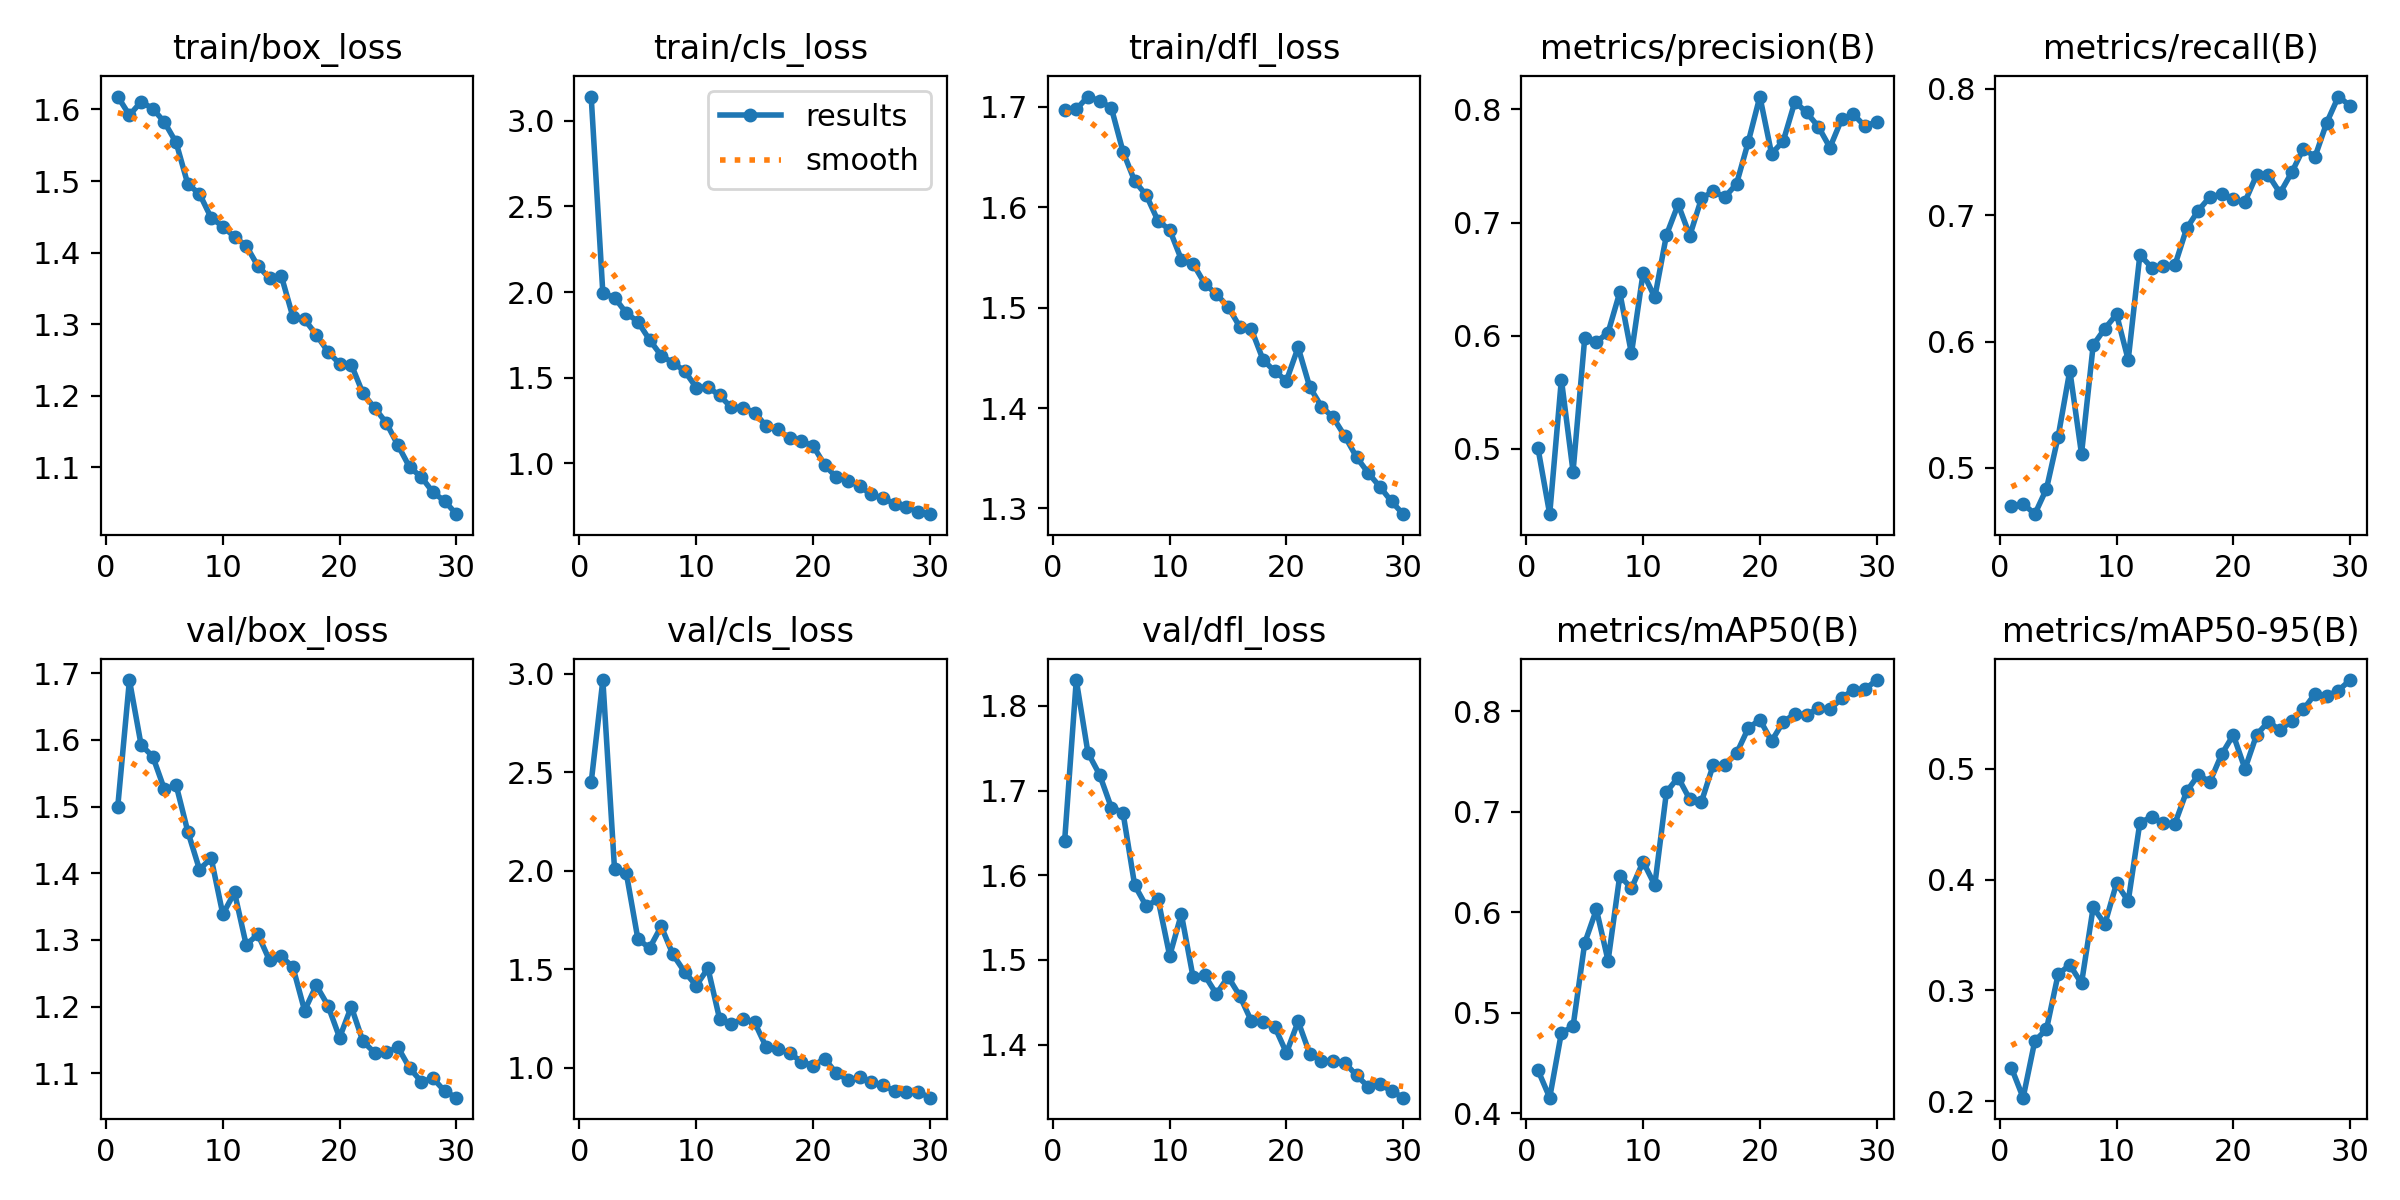


Cara membaca (Slide 33):
  * box_loss turun  -> regresi bounding box makin presisi.
  * cls_loss turun  -> klasifikasi kelas makin benar.
  * dfl_loss turun  -> distribusi tepi bbox makin tajam.
  * Bila val_loss NAIK sementara train_loss turun -> OVERFITTING:
    tambah augmentasi, kurangi epoch, atau perbanyak data.



In [19]:
# =============================================================================
#  TAHAP 6a — KURVA TRAINING (results.png & box_loss/cls_loss/dfl_loss) — Slide 33
# =============================================================================
from IPython.display import Image, display as disp
import matplotlib.pyplot as plt

# 1) results.png bawaan Ultralytics (loss train & val + metrik)
if (SAVE_DIR / "results.png").exists():
    shutil.copy2(SAVE_DIR / "results.png", OUT_DIR / "results.png")
    print("[OK] results.png — ringkasan semua kurva (loss + metrik)")
    disp(Image(filename=str(OUT_DIR / "results.png"), width=980))
else:
    print("[!] results.png tidak ditemukan. Pastikan model.train(plots=True).")

# 2) plot manual box_loss, cls_loss, dfl_loss (train vs val)
csv = pd.read_csv(SAVE_DIR / "results.csv")
csv.columns = [c.strip() for c in csv.columns]
pasangan = [("train/box_loss", "val/box_loss", "box_loss (bbox regression)"),
            ("train/cls_loss", "val/cls_loss", "cls_loss (klasifikasi)"),
            ("train/dfl_loss", "val/dfl_loss", "dfl_loss (distribution focal)")]
tersedia = [p for p in pasangan if p[0] in csv.columns and p[1] in csv.columns]

if tersedia:
    fig, axes = plt.subplots(1, len(tersedia), figsize=(5*len(tersedia), 4))
    if len(tersedia) == 1: axes = [axes]
    for ax, (kt, kv, judul) in zip(axes, tersedia):
        ax.plot(csv["epoch"], csv[kt], label="train", linewidth=1.8)
        ax.plot(csv["epoch"], csv[kv], label="val", linewidth=1.8, linestyle="--")
        ax.set_title(judul); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
        ax.legend(); ax.grid(alpha=0.3)
    fig.suptitle("Kurva Loss Training vs Validasi (Slide 33)", fontweight="bold")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "training_curves.png", dpi=130, bbox_inches="tight")
    plt.show()
    print('''
Cara membaca (Slide 33):
  * box_loss turun  -> regresi bounding box makin presisi.
  * cls_loss turun  -> klasifikasi kelas makin benar.
  * dfl_loss turun  -> distribusi tepi bbox makin tajam.
  * Bila val_loss NAIK sementara train_loss turun -> OVERFITTING:
    tambah augmentasi, kurangi epoch, atau perbanyak data.
''')


[OK] confusion_matrix_normalized.png


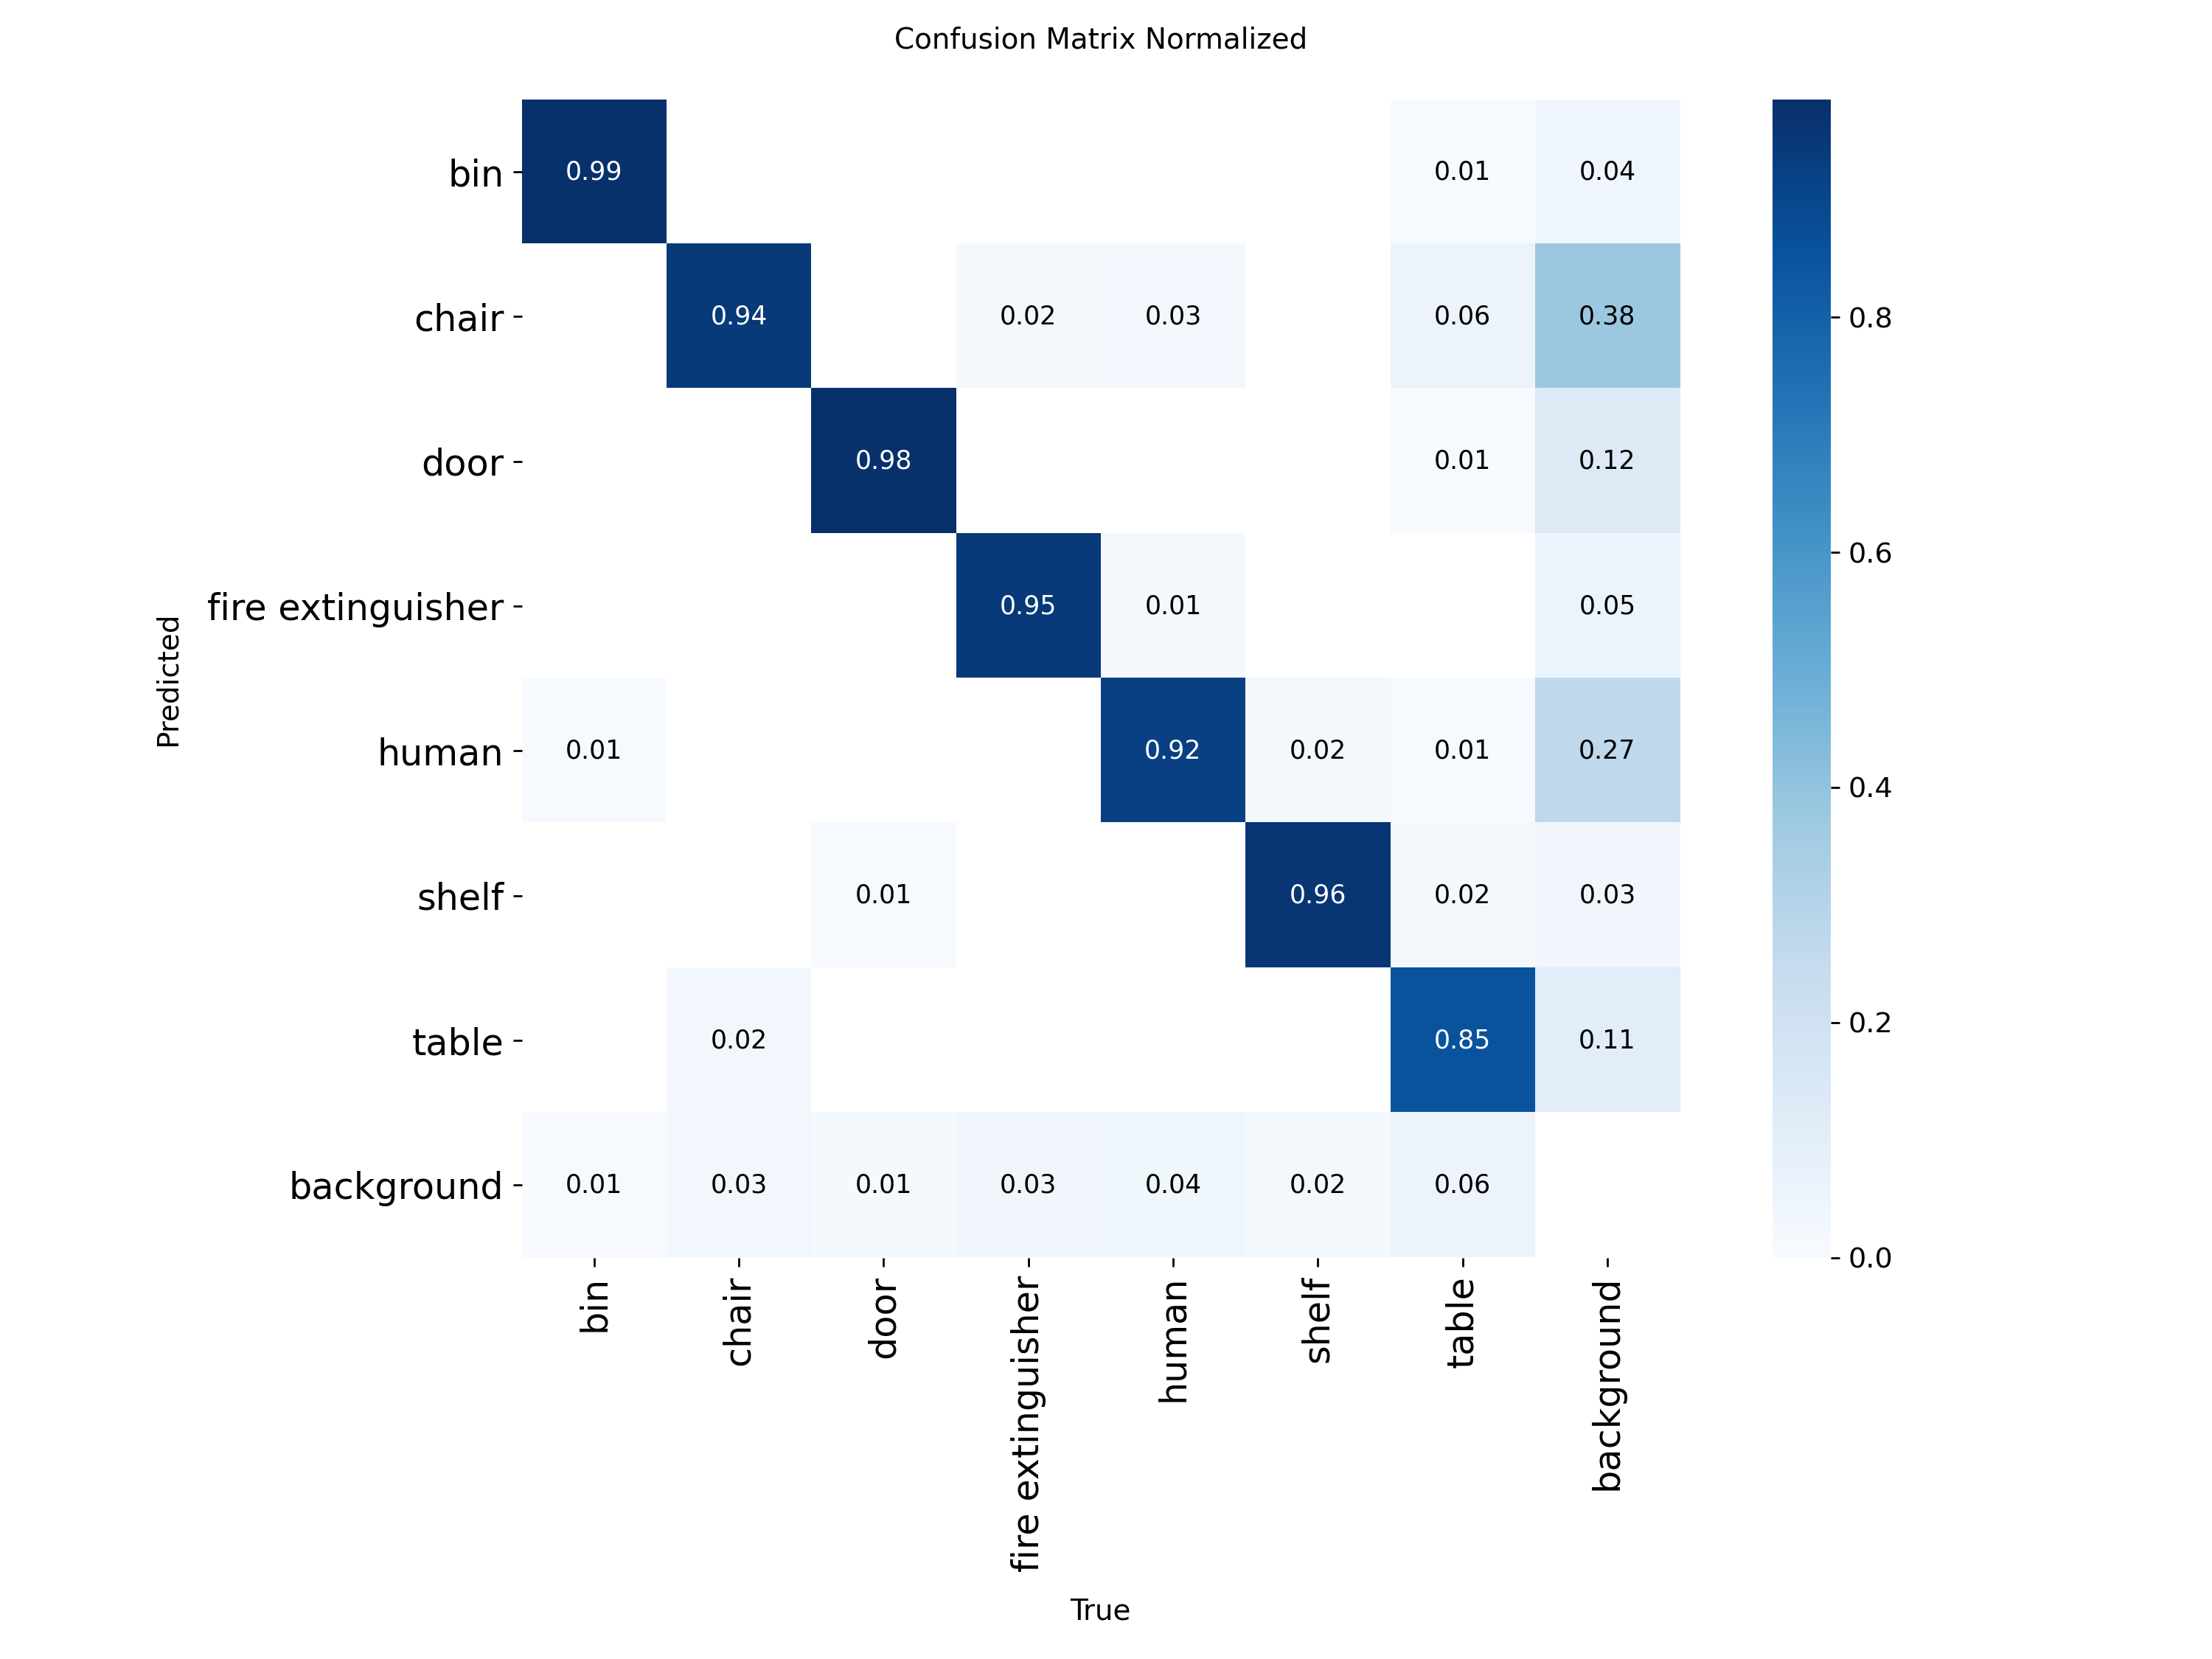

[OK] confusion_matrix.png


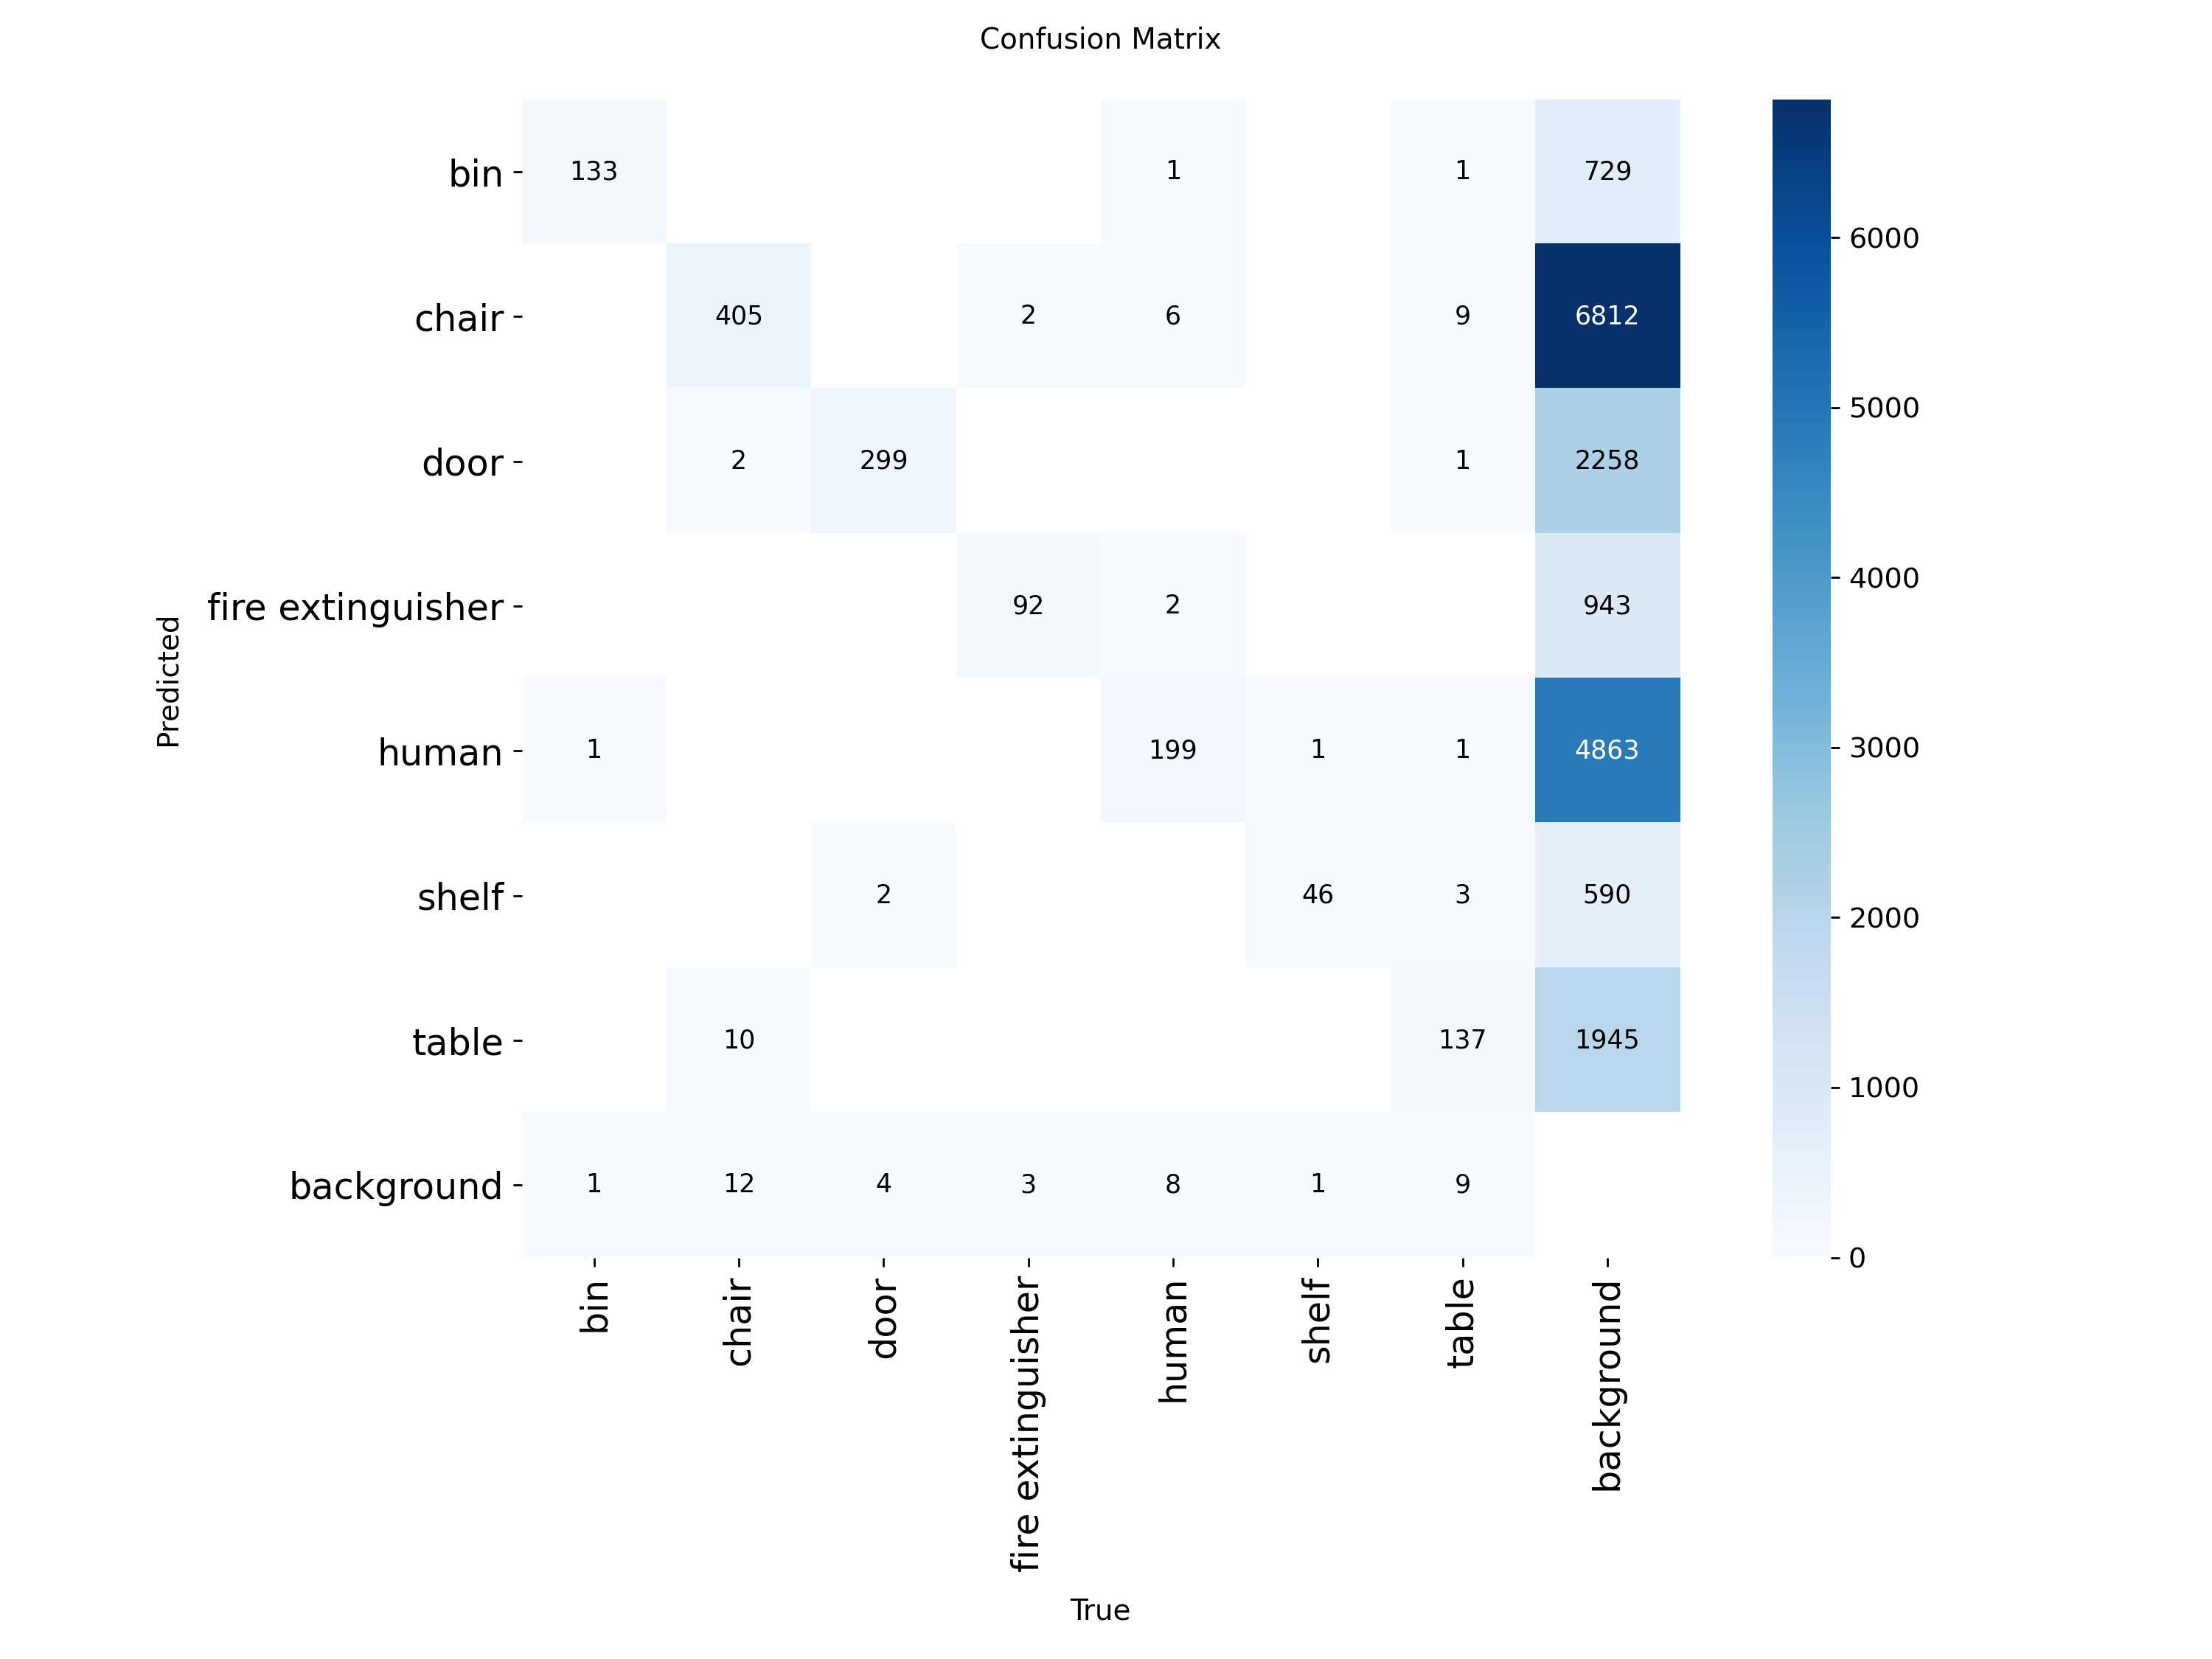


Cara membaca (Slide 34):
  * Diagonal = prediksi BENAR. Makin gelap/tinggi makin baik.
  * Baris = kelas sebenarnya (ground truth), kolom = prediksi model.
  * Nilai di luar diagonal = kesalahan klasifikasi. Contoh khas dataset ini:
    'chair' <-> 'table' dan 'door' <-> 'shelf' sering tertukar karena bentuknya mirip.
  * Kolom/baris 'background' menunjukkan false positive (objek dideteksi padahal
    tidak ada) dan false negative (objek ada tapi tidak terdeteksi).



In [20]:
# =============================================================================
#  TAHAP 6b — CONFUSION MATRIX (Slide 34)
# =============================================================================
tampil_cm = False
for nama in ["confusion_matrix_normalized.png", "confusion_matrix.png"]:
    f = SAVE_DIR / nama
    if not f.exists():
        f = RUNS_DIR / f"ets_indoor_test" / nama
    if f.exists():
        shutil.copy2(f, OUT_DIR / nama)
        print(f"[OK] {nama}")
        disp(Image(filename=str(OUT_DIR / nama), width=720))
        tampil_cm = True
if not tampil_cm:
    print("[!] Confusion matrix belum ada. Pastikan val() dijalankan dengan plots=True.")

print('''
Cara membaca (Slide 34):
  * Diagonal = prediksi BENAR. Makin gelap/tinggi makin baik.
  * Baris = kelas sebenarnya (ground truth), kolom = prediksi model.
  * Nilai di luar diagonal = kesalahan klasifikasi. Contoh khas dataset ini:
    'chair' <-> 'table' dan 'door' <-> 'shelf' sering tertukar karena bentuknya mirip.
  * Kolom/baris 'background' menunjukkan false positive (objek dideteksi padahal
    tidak ada) dan false negative (objek ada tapi tidak terdeteksi).
''')


In [21]:
# =============================================================================
#  TAHAP 6c — val_batch0_labels.jpg  vs  val_batch0_pred.jpg  (Slide 35)
# =============================================================================
import numpy as np
import cv2
import matplotlib.pyplot as plt

def cari_file(nama: str) -> Path | None:
    for kandidat in [SAVE_DIR / nama, RUNS_DIR / "ets_indoor_test" / nama,
                     OUT_DIR / nama]:
        if kandidat.exists():
            return kandidat
    return None

f_label = cari_file("val_batch0_labels.jpg")
f_pred  = cari_file("val_batch0_pred.jpg")

if f_label and f_pred:
    shutil.copy2(f_label, OUT_DIR / "val_batch0_labels.jpg")
    shutil.copy2(f_pred, OUT_DIR / "val_batch0_pred.jpg")

    kiri  = cv2.imread(str(f_label))
    kanan = cv2.imread(str(f_pred))
    tinggi = min(kiri.shape[0], kanan.shape[0])
    skala_k = tinggi / kiri.shape[0]; skala_n = tinggi / kanan.shape[0]
    kiri  = cv2.resize(kiri,  (int(kiri.shape[1]*skala_k),  tinggi))
    kanan = cv2.resize(kanan, (int(kanan.shape[1]*skala_n), tinggi))
    jarak = 12
    gabung = np.full((tinggi + 40, kiri.shape[1] + kanan.shape[1] + jarak, 3), 255, np.uint8)
    gabung[40:, :kiri.shape[1]] = kiri
    gabung[40:, kiri.shape[1]+jarak:] = kanan
    cv2.putText(gabung, "GROUND TRUTH (labels)", (8, 28),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2, cv2.LINE_AA)
    cv2.putText(gabung, "PREDIKSI MODEL", (kiri.shape[1] + jarak + 8, 28),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2, cv2.LINE_AA)
    cv2.imwrite(str(OUT_DIR / "perbandingan_labels_vs_pred.jpg"), gabung)
    print("[OK] Perbandingan disimpan: perbandingan_labels_vs_pred.jpg")
    plt.figure(figsize=(16, 7))
    plt.imshow(gabung[:, :, ::-1]); plt.axis("off")
    plt.title("val_batch0_labels.jpg (kiri) vs val_batch0_pred.jpg (kanan) — Slide 35")
    plt.tight_layout(); plt.show()
    print('''
Cara menganalisis (Slide 35):
  * Bandingkan jumlah & posisi bbox: apakah ada objek GT yang tidak terdeteksi
    (false negative) atau bbox tambahan (false positive)?
  * Perhatikan bbox yang bergeser/terlalu besar-kecil -> pengaruh IoU ke mAP50-95.
  * Cek label yang salah kelas (mis. 'table' diprediksi 'chair').
''')
else:
    print("[!] val_batch0_labels.jpg / val_batch0_pred.jpg tidak ditemukan.")


[OK] Perbandingan disimpan: perbandingan_labels_vs_pred.jpg

Cara menganalisis (Slide 35):
  * Bandingkan jumlah & posisi bbox: apakah ada objek GT yang tidak terdeteksi
    (false negative) atau bbox tambahan (false positive)?
  * Perhatikan bbox yang bergeser/terlalu besar-kecil -> pengaruh IoU ke mAP50-95.
  * Cek label yang salah kelas (mis. 'table' diprediksi 'chair').



---
## 🔍 Tahap 7 — Inferensi & Perbandingan Model (Slide 32, 36)

Dua hal yang diuji:

1. **Pre-trained COCO vs Custom Model** — membuktikan nilai transfer learning.
   `yolo12n.pt` hanya tahu 80 kelas COCO (person, chair, dining table, ...),
   sehingga `bin`, `door`, `fire extinguisher`, `shelf` **tidak dikenali**.
   Setelah fine-tuning, `MyYOLOModel.pt` mengenali 7 kelas indoor.
2. **Uji gambar statis** (Slide 36):
   `model = YOLO("MyYOLOModel.pt")` → `results = model("foto.jpg")` → simpan bbox.


In [22]:
# =============================================================================
#  TAHAP 7a — PERBANDINGAN PRE-TRAINED COCO vs CUSTOM MODEL (Slide 32)
# =============================================================================
from ultralytics import YOLO
import numpy as np, cv2, matplotlib.pyplot as plt

model_custom = YOLO(str(MODEL_FINAL))
model_coco = YOLO("yolo11n.pt" if MODEL_NAME.startswith("yolo11") else "yolo12n.pt")
print("[OK] Kedua model siap")

contoh = sorted((DATASET_DIR / "test" / "images").glob("*.jpg"))[:4]
if not contoh:
    print("[!] Tidak ada gambar test.")
else:
    fig, axes = plt.subplots(len(contoh), 2, figsize=(13, 4.4 * len(contoh)))
    if len(contoh) == 1:
        axes = np.array([axes])
    for baris_i, img_path in enumerate(contoh):
        for kolom, (judul, mdl) in enumerate([("Pre-trained COCO", model_coco),
                                              ("Custom MyYOLOModel.pt", model_custom)]):
            r = mdl.predict(source=str(img_path), conf=0.25, imgsz=IMGSZ,
                            device=DEVICE, verbose=False)[0]
            jumlah = Counter(mdl.names[int(c)] for c in r.boxes.cls.tolist()) \
                     if r.boxes is not None and len(r.boxes) else Counter()
            ax = axes[baris_i][kolom]
            ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
            ax.set_title(f"{judul}\n{', '.join(f'{k}:{v}' for k, v in jumlah.items()) or 'tidak ada objek'}",
                         fontsize=9)
            ax.axis("off")
    fig.suptitle("Pre-trained COCO vs Custom Model — bukti transfer learning (Slide 32)",
                 fontweight="bold")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "compare_coco_vs_custom.png", dpi=130, bbox_inches="tight")
    plt.show()
    print('''
Analisis (Slide 32):
  * COCO hanya punya kelas umum (person, chair, dining table, ...). Objek seperti
    bin / door / fire extinguisher / shelf TIDAK terdeteksi -> bukti bahwa model
    pre-trained belum cukup untuk kebutuhan spesifik.
  * Custom model mendeteksi 7 kelas indoor dengan bbox yang jauh lebih tepat.
  * Perhatikan juga 'person' di COCO vs 'human' di custom model.
''')


[OK] Kedua model siap

Analisis (Slide 32):
  * COCO hanya punya kelas umum (person, chair, dining table, ...). Objek seperti
    bin / door / fire extinguisher / shelf TIDAK terdeteksi -> bukti bahwa model
    pre-trained belum cukup untuk kebutuhan spesifik.
  * Custom model mendeteksi 7 kelas indoor dengan bbox yang jauh lebih tepat.
  * Perhatikan juga 'person' di COCO vs 'human' di custom model.



In [23]:
# =============================================================================
#  TAHAP 7b — UJI GAMBAR STATIS (Slide 36) + OBJECT COUNTING
# =============================================================================
_MODEL_CACHE = None

def prediksi_gambar(path_gambar, simpan=True, tampilkan=True, conf=0.25):
    '''Pola dosen: model = YOLO("MyYOLOModel.pt"); results = model(path)'''
    global _MODEL_CACHE
    if _MODEL_CACHE is None:
        _MODEL_CACHE = YOLO(str(MODEL_FINAL))
    model = _MODEL_CACHE
    results = model(str(path_gambar), conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)

    for i, r in enumerate(results):
        jumlah = Counter(model.names[int(c)] for c in r.boxes.cls.tolist()) \
                 if r.boxes is not None and len(r.boxes) else Counter()
        print(f"  Gambar: {Path(path_gambar).name}")
        print(f"  Objek terdeteksi: {sum(jumlah.values())} -> "
              f"{dict(jumlah) if jumlah else 'tidak ada'}")
        st = Path(path_gambar).stem
        out = HASIL_DIR / f"{st}_pred.jpg"
        r.save(filename=str(out))                 # simpan bbox
        if simpan:
            cv2.imwrite(str(HASIL_DIR / "detection_result.jpg"),
                        cv2.imread(str(out)))         # nama wajib slide 37
        if tampilkan:
            fig, ax = plt.subplots(1, 2, figsize=(13, 5))
            ax[0].imshow(cv2.cvtColor(cv2.imread(str(path_gambar)), cv2.COLOR_BGR2RGB))
            ax[0].set_title("Input"); ax[0].axis("off")
            ax[1].imshow(cv2.cvtColor(cv2.imread(str(out)), cv2.COLOR_BGR2RGB))
            ax[1].set_title(f"Prediksi — total {sum(jumlah.values())} objek")
            ax[1].axis("off")
            plt.tight_layout(); plt.show()
        return out, jumlah

# --- uji otomatis pada 3 gambar test ---
print("=== UJI CEPAT PADA 3 GAMBAR TEST ===")
for p in sorted((DATASET_DIR / "test" / "images").glob("*.jpg"))[:3]:
    prediksi_gambar(p, tampilkan=False)
print(f"\n[i] Hasil tersimpan di {HASIL_DIR}")
print("[i] detection_result.jpg siap dipakai untuk laporan (Slide 37).")


=== UJI CEPAT PADA 3 GAMBAR TEST ===
  Gambar: IMG20231229165718_jpg.rf.69f3cd32534e0b49656f2b784c61f778.jpg
  Objek terdeteksi: 4 -> {'human': 4}
  Gambar: IMG20250301221616_jpg.rf.1e444cc0c046415076a5077039a9350b.jpg
  Objek terdeteksi: 2 -> {'bin': 1, 'door': 1}
  Gambar: IMG20250302162029_jpg.rf.006d2ba6160636fa093491dff6371c72.jpg
  Objek terdeteksi: 5 -> {'shelf': 2, 'door': 1, 'chair': 1, 'bin': 1}

[i] Hasil tersimpan di /content/hasil_inferensi
[i] detection_result.jpg siap dipakai untuk laporan (Slide 37).


In [24]:
# =============================================================================
#  TAHAP 7c — UPLOAD FOTO SENDIRI (Slide 36)
#  Unggah foto objek indoor dari HP/laptop, model akan menggambar bbox.
# =============================================================================
from google.colab import files as colab_files

print("[*] Silakan pilih 1-5 foto (jpg/png) objek indoor: kursi, meja, pintu, "
      "manusia, tempat sampah, rak, APAR...")
unggahan = colab_files.upload()
print(f"[OK] {len(unggahan)} file diunggah: {list(unggahan.keys())}")

for nama_file, isi in unggahan.items():
    path_masuk = HASIL_DIR / f"upload_{nama_file}"
    path_masuk.write_bytes(isi)
    prediksi_gambar(path_masuk, conf=0.25)

print(f"\n[OK] Semua hasil upload tersimpan di {HASIL_DIR}")


[*] Silakan pilih 1-5 foto (jpg/png) objek indoor: kursi, meja, pintu, manusia, tempat sampah, rak, APAR...


Saving IMG_3041_MOV-0068_jpg.rf.f355cd63ea432d1ae1f5e37fac5a34d7.jpg to IMG_3041_MOV-0068_jpg.rf.f355cd63ea432d1ae1f5e37fac5a34d7.jpg
[OK] 1 file diunggah: ['IMG_3041_MOV-0068_jpg.rf.f355cd63ea432d1ae1f5e37fac5a34d7.jpg']
  Gambar: upload_IMG_3041_MOV-0068_jpg.rf.f355cd63ea432d1ae1f5e37fac5a34d7.jpg
  Objek terdeteksi: 14 -> {'chair': 13, 'human': 1}

[OK] Semua hasil upload tersimpan di /content/hasil_inferensi


In [25]:
# =============================================================================
#  TAHAP 7d — WEBCAM BROWSER (JavaScript) — Slide 29 & 37
#  Colab tidak bisa mengakses webcam lewat cv2.VideoCapture(0) karena berjalan
#  di server, jadi dipakai JavaScript getUserMedia di browser + ambil frame.
#  (Untuk webcam native OpenCV, jalankan scripts_lokal/4_indoor_security_webcam.py)
# =============================================================================
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import cv2, numpy as np
import matplotlib.pyplot as plt
from collections import Counter as _Counter

def ambil_foto_webcam(kualitas=0.9, teks_tombol="📸 Ambil Gambar"):
    '''Buka webcam browser, tunggu tombol diklik, kembalikan gambar (numpy BGR).'''
    js = Javascript('''
      async function ambilFoto(kualitas, teksTombol) {
        const div = document.createElement('div');
        const tombol = document.createElement('button');
        tombol.textContent = teksTombol;
        tombol.style.cssText = 'font-size:16px;padding:8px 16px;margin:8px 0;cursor:pointer';
        div.appendChild(tombol);

        const video = document.createElement('video');
        video.style.display = 'block';
        video.style.maxWidth = '100%';
        div.appendChild(video);
        document.body.appendChild(div);

        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        video.srcObject = stream;
        await video.play();
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

        await new Promise((resolve, reject) => {
          tombol.onclick = resolve;
        });

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getVideoTracks()[0].stop();
        div.remove();
        return canvas.toDataURL('image/jpeg', kualitas);
      }
''')
    display(js)
    data_url = eval_js(f"ambilFoto({kualitas}, '{teks_tombol}')")
    biner = b64decode(data_url.split(",")[1])
    arr = np.frombuffer(biner, np.uint8)
    return cv2.imdecode(arr, cv2.IMREAD_COLOR)


try:
    frame = ambil_foto_webcam()
    path_webcam = HASIL_DIR / "webcam_capture.jpg"
    cv2.imwrite(str(path_webcam), frame)
    print(f"[OK] Frame webcam: {frame.shape[1]}x{frame.shape[0]} px -> {path_webcam.name}")

    model = YOLO(str(MODEL_FINAL))
    hasil = model.predict(source=frame, conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    jumlah = _Counter(model.names[int(c)] for c in hasil.boxes.cls.tolist()) \
             if hasil.boxes is not None and len(hasil.boxes) else _Counter()

    beranotasi = hasil.plot()
    cv2.putText(beranotasi, f"TOTAL: {sum(jumlah.values())} objek", (14, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2, cv2.LINE_AA)
    cv2.imwrite(str(HASIL_DIR / "detection_result.jpg"), beranotasi)

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ax[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); ax[0].set_title("Webcam"); ax[0].axis("off")
    ax[1].imshow(cv2.cvtColor(beranotasi, cv2.COLOR_BGR2RGB))
    ax[1].set_title(f"Deteksi: {dict(jumlah) if jumlah else 'tidak ada objek'}")
    ax[1].axis("off")
    plt.tight_layout(); plt.show()

    print(f"\nObjek terdeteksi: {sum(jumlah.values())}")
    for k, v in jumlah.most_common():
        print(f"  {k:<20}: {v}")
    print(f"[OK] detection_result.jpg tersimpan di {HASIL_DIR}")
except Exception as exc:
    print(f"[!] Webcam browser tidak tersedia / izin ditolak: {exc}")
    print("    Alternatif: jalankan scripts_lokal/4_indoor_security_webcam.py di VS Code lokal,")
    print("    atau gunakan sel upload foto di atas.")


<IPython.core.display.Javascript object>

[!] Webcam browser tidak tersedia / izin ditolak: NotAllowedError: Permission denied
    Alternatif: jalankan scripts_lokal/4_indoor_security_webcam.py di VS Code lokal,
    atau gunakan sel upload foto di atas.


---
## 🎥 Tahap 8 — Indoor Security Camera + Object Counting (Slide 3, 37, 38)

Fitur yang diminta dosen: **kamera keamanan ruangan** yang
① menghitung objek, ② menyimpan gambar saat objek terdeteksi, ③ merekam video.

Di Colab tidak ada akses webcam native, jadi sel di bawah **menyimulasikan** kamera
keamanan memakai gambar *test set* sebagai frame video — hasilnya tetap file `.mp4`
nyata + `detection_result.jpg`. Untuk webcam sungguhan, jalankan versi OpenCV di laptop:

```bash
python scripts_lokal/4_indoor_security_webcam.py --targets human door
```


In [26]:
# =============================================================================
#  TAHAP 8 — SIMULASI SECURITY CAMERA: object counter + auto-save + auto-record
#  (versi Colab; padanan dari scripts_lokal/4_indoor_security_webcam.py)
# =============================================================================
from ultralytics import YOLO
import cv2, numpy as np, time
from collections import Counter

TARGETS = set(AKTIF_KELAS)      # ubah mis. {"human", "door"} untuk alarm terbatas
FPS_VIDEO = 8
MAKS_FRAME = 40                 # jumlah frame video simulasi

model = YOLO(str(MODEL_FINAL))
frame_paths = sorted((DATASET_DIR / "test" / "images").glob("*.jpg"))[:MAKS_FRAME]
print(f"[*] {len(frame_paths)} frame test akan dipakai sebagai video simulasi")

WARNA = {"bin": (0,165,255), "chair": (255,144,30), "door": (60,200,60),
         "fire extinguisher": (40,40,230), "human": (230,90,200),
         "shelf": (200,200,60), "table": (150,110,255)}

def panel_counter(frame, jumlah, total_unik, fps, tunda_kejadian):
    '''Panel object counter semi-transparan.'''
    h = 124 + 22 * max(len(jumlah), 1)   # judul + total + FPS + n baris + status
    ov = frame.copy()
    cv2.rectangle(ov, (10,10), (330, 10+h), (25,25,25), -1)
    cv2.addWeighted(ov, 0.62, frame, 0.38, 0, frame)
    cv2.rectangle(frame, (10,10), (330, 10+h), (0,255,0) if jumlah else (170,170,170), 2)
    y = 36
    cv2.putText(frame, "INDOOR SECURITY CAMERA", (22,y), cv2.FONT_HERSHEY_SIMPLEX,
                0.55, (255,255,255), 2, cv2.LINE_AA); y += 24
    cv2.putText(frame, f"Objek di frame: {sum(jumlah.values())}", (22,y),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0,255,255), 2, cv2.LINE_AA); y += 22
    cv2.putText(frame, f"FPS: {fps:.1f}", (22,y), cv2.FONT_HERSHEY_SIMPLEX,
                0.45, (200,200,200), 1, cv2.LINE_AA); y += 24
    for nama, n in jumlah.most_common():
        cv2.rectangle(frame, (22, y-9), (34, y+3), WARNA.get(nama, (0,255,0)), -1)
        cv2.putText(frame, f"{nama}: {n} (total {total_unik[nama]})", (42,y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1, cv2.LINE_AA)
        y += 22
    if not jumlah:
        cv2.putText(frame, "menunggu objek...", (22,y), cv2.FONT_HERSHEY_SIMPLEX,
                    0.5, (150,150,150), 1, cv2.LINE_AA)
    if tunda_kejadian:
        cv2.circle(frame, (frame.shape[1]-38, 38), 11, (0,0,255), -1)
        cv2.putText(frame, "REC", (frame.shape[1]-96, 45), cv2.FONT_HERSHEY_SIMPLEX,
                    0.7, (0,0,255), 2, cv2.LINE_AA)
    return frame

writer = None
video_path = HASIL_DIR / "security_camera_recording.mp4"
total_unik = Counter()
snapshot_dibuat = []
t0 = time.time()

for i, fp in enumerate(frame_paths):
    img = cv2.imread(str(fp))
    hasil = model.predict(source=img, conf=0.3, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    jumlah = Counter(model.names[int(c)] for c in hasil.boxes.cls.tolist()) \
             if hasil.boxes is not None and len(hasil.boxes) else Counter()
    total_unik.update(jumlah)

    frame_out = hasil.plot()
    fps_sim = min(1.0 / max(time.time() - t0, 1e-3), 999.0)
    frame_out = panel_counter(frame_out, jumlah, total_unik, fps_sim,
                              bool(TARGETS & set(jumlah)))

    # auto-save saat objek target terdeteksi
    if TARGETS & set(jumlah):
        cv2.imwrite(str(HASIL_DIR / "detection_result.jpg"), frame_out)
        if len(snapshot_dibuat) < 6:
            p = HASIL_DIR / f"security_snapshot_{i:03d}.jpg"
            cv2.imwrite(str(p), frame_out)
            snapshot_dibuat.append(p)

    # auto-record
    if writer is None:
        writer = cv2.VideoWriter(str(video_path), cv2.VideoWriter_fourcc(*"mp4v"),
                                 FPS_VIDEO, (frame_out.shape[1], frame_out.shape[0]))
    writer.write(frame_out)

    if (i + 1) % 10 == 0:
        print(f"  frame {i+1}/{len(frame_paths)} | objek sekarang: {sum(jumlah.values())} "
              f"| total unik: {dict(total_unik)}")

if writer is not None:
    writer.release()

print(f"\n[OK] Rekaman video: {video_path} "
      f"({video_path.stat().st_size/1024:.0f} KB)")
print(f"[OK] Snapshot otomatis: {len(snapshot_dibuat)} file + detection_result.jpg")
print(f"[i] Total objek unik terlihat: {dict(total_unik)}")


[*] 40 frame test akan dipakai sebagai video simulasi
  frame 10/40 | objek sekarang: 2 | total unik: {'human': 3, 'bin': 3, 'door': 4, 'shelf': 4, 'chair': 5}
  frame 20/40 | objek sekarang: 1 | total unik: {'human': 3, 'bin': 4, 'door': 9, 'shelf': 7, 'chair': 12, 'table': 5}
  frame 30/40 | objek sekarang: 1 | total unik: {'human': 3, 'bin': 8, 'door': 17, 'shelf': 7, 'chair': 12, 'table': 5, 'fire extinguisher': 1}
  frame 40/40 | objek sekarang: 1 | total unik: {'human': 3, 'bin': 9, 'door': 26, 'shelf': 9, 'chair': 13, 'table': 5, 'fire extinguisher': 2}

[OK] Rekaman video: /content/hasil_inferensi/security_camera_recording.mp4 (1936 KB)
[OK] Snapshot otomatis: 6 file + detection_result.jpg
[i] Total objek unik terlihat: {'human': 3, 'bin': 9, 'door': 26, 'shelf': 9, 'chair': 13, 'table': 5, 'fire extinguisher': 2}


In [27]:
# =============================================================================
#  TAHAP 8b — PUTAR HASIL REKAMAN DI NOTEBOOK + tampilkan snapshot terbaik
# =============================================================================
from IPython.display import HTML, display as disp
from base64 import b64encode
import matplotlib.pyplot as plt
import cv2

if video_path.exists():
    data = b64encode(video_path.read_bytes()).decode()
    disp(HTML(f'''
      <video width="720" controls autoplay loop muted
             style="border:2px solid #333;border-radius:8px">
        <source src="data:video/mp4;base64,{data}" type="video/mp4">
      </video>
      <p><i>Hasil rekaman otomatis saat objek target terdeteksi (Slide 38)</i></p>
    '''))
else:
    print("[!] Video belum dibuat.")

snap = sorted(HASIL_DIR.glob("security_snapshot_*.jpg"))[:4]
if snap:
    fig, axes = plt.subplots(1, len(snap), figsize=(4.2*len(snap), 4))
    if len(snap) == 1: axes = [axes]
    for ax, p in zip(axes, snap):
        ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
        ax.set_title(p.name, fontsize=8); ax.axis("off")
    fig.suptitle("Snapshot otomatis saat objek target terdeteksi (Slide 37)")
    fig.tight_layout(); plt.show()


In [28]:
# =============================================================================
#  TAHAP 9 — EKSPOR ONNX (opsional, Slide 25)
# =============================================================================
if EXPORT_ONNX:
    from ultralytics import YOLO
    print("[*] Mengekspor MyYOLOModel.pt -> ONNX (opset 12)...")
    jalur = YOLO(str(MODEL_FINAL)).export(format="onnx", imgsz=IMGSZ, opset=12, dynamic=False)
    onnx_path = BASE / "MyYOLOModel.onnx"
    shutil.copy2(jalur, onnx_path)
    print(f"[OK] {onnx_path} ({onnx_path.stat().st_size/1e6:.2f} MB)")
    print("    ONNX dipakai untuk deployment tanpa PyTorch (mis. OpenCV DNN, TensorRT).")
else:
    print("[i] EXPORT_ONNX = False -> lewati. Ubah ke True di Panel Kontrol bila diminta.")


[i] EXPORT_ONNX = False -> lewati. Ubah ke True di Panel Kontrol bila diminta.


---
## 📦 Tahap 10 — Unduh Hasil (`Hasil_ETS_ObjectDetection.zip`)

Isi ZIP:
- `MyYOLOModel.pt` (model hasil training)
- `data.yaml`, `class_distribution.png`, `map_per_class.png`
- `ETS_results/`: `results.png`, `training_curves.png`, `confusion_matrix.png`,
  `val_batch0_labels.jpg`, `val_batch0_pred.jpg`, `perbandingan_labels_vs_pred.jpg`,
  `compare_coco_vs_custom.png`, `metrics_summary.txt`, metrik per kelas (CSV)
- `hasil_inferensi/`: `detection_result.jpg`, `security_camera_recording.mp4`, snapshot
- `metrics.json` (metrik ringkas dalam format mesin)

> Jika ZIP gagal diunduh otomatis (batas browser), buka panel **Files** di kiri Colab
> lalu klik-kanan file ZIP ▸ *Download*.


In [29]:
# =============================================================================
#  TAHAP 10 — BUNDEL SEMUA HASIL -> Hasil_ETS_ObjectDetection.zip + unduh 1 klik
# =============================================================================
import json
from pathlib import Path

BUNDEL = BASE / "Hasil_ETS_ObjectDetection"
if BUNDEL.exists():
    shutil.rmtree(BUNDEL)
BUNDEL.mkdir(parents=True)

# 1) model & konfigurasi
if MODEL_FINAL.exists():
    shutil.copy2(MODEL_FINAL, BUNDEL / "MyYOLOModel.pt")
if (BASE / "MyYOLOModel.onnx").exists():
    shutil.copy2(BASE / "MyYOLOModel.onnx", BUNDEL / "MyYOLOModel.onnx")
if DATA_YAML.exists():
    shutil.copy2(DATA_YAML, BUNDEL / "data.yaml")
for f in [GRAFIK_DIST, GRAFIK_MAP]:
    if Path(f).exists():
        shutil.copy2(f, BUNDEL / Path(f).name)

# 2) artefak evaluasi
if OUT_DIR.exists():
    shutil.copytree(OUT_DIR, BUNDEL / "ETS_results", dirs_exist_ok=True)

# 3) hasil inferensi & rekaman
if HASIL_DIR.exists():
    shutil.copytree(HASIL_DIR, BUNDEL / "hasil_inferensi", dirs_exist_ok=True)

# 5) metrik ringkas (JSON) untuk analisis cepat
metrik = {
    "nama": "Muhammad Zahran Razzaq",
    "nrp": "5024xxxxxx",
    "model_pretrained": MODEL_NAME,
    "kelas": AKTIF_KELAS,
    "jumlah_kelas": len(AKTIF_KELAS),
    "epochs": EPOCHS, "patience": PATIENCE, "imgsz": IMGSZ, "batch": BATCH,
    "durasi_training_menit": round(DURASI_TRAIN / 60, 2),
    "jumlah_gambar": {s: int(STAT["gambar"][s]) for s in SPLITS},
    "instance_per_kelas": {k: int(STAT["kelas"][k]) for k in AKTIF_KELAS},
    "validation": {"P": round(float(metrics_val.box.mp), 4),
                   "R": round(float(metrics_val.box.mr), 4),
                   "mAP50": round(float(metrics_val.box.map50), 4),
                   "mAP50-95": round(float(metrics_val.box.map), 4)},
    "test": {"P": round(float(metrics_test.box.mp), 4),
             "R": round(float(metrics_test.box.mr), 4),
             "mAP50": round(float(metrics_test.box.map50), 4),
             "mAP50-95": round(float(metrics_test.box.map), 4)},
    "per_kelas_test": df_test.to_dict(orient="records"),
}
(BUNDEL / "metrics.json").write_text(json.dumps(metrik, indent=2, ensure_ascii=False),
                                     encoding="utf-8")

# 6) README singkat di dalam ZIP
readme = f'''HASIL ETS ELEKTRONIKA CERDAS — OBJECT DETECTION (INDOOR)
Nama : Muhammad Zahran Razzaq
NRP  : 5024xxxxxx

Model pre-trained : {MODEL_NAME}
Kelas ({len(AKTIF_KELAS)})            : {AKTIF_KELAS}
Training          : {EPOCHS} epoch (patience {PATIENCE}), imgsz {IMGSZ}, batch {BATCH}
Durasi training   : {DURASI_TRAIN/60:.1f} menit

VALIDATION -> P={metrics_val.box.mp:.4f}  R={metrics_val.box.mr:.4f}  \
mAP50={metrics_val.box.map50:.4f}  mAP50-95={metrics_val.box.map:.4f}
TEST       -> P={metrics_test.box.mp:.4f}  R={metrics_test.box.mr:.4f}  \
mAP50={metrics_test.box.map50:.4f}  mAP50-95={metrics_test.box.map:.4f}

Isi folder:
  MyYOLOModel.pt           : model hasil transfer learning
  data.yaml                : konfigurasi dataset (path absolut)
  class_distribution.png   : distribusi kelas (Slide 31)
  map_per_class.png        : mAP per kelas (Slide 32)
  ETS_results/             : results.png, training_curves.png, confusion_matrix.png,
                             val_batch0_labels.jpg, val_batch0_pred.jpg,
                             perbandingan_labels_vs_pred.jpg, compare_coco_vs_custom.png,
                             metrics_summary.txt, per-class CSV
  hasil_inferensi/         : detection_result.jpg, security_camera_recording.mp4, snapshot
  metrics.json             : metrik dalam format mesin
'''
(BUNDEL / "README_HASIL.txt").write_text(readme, encoding="utf-8")

# 7) kompres
zip_final = BASE / "Hasil_ETS_ObjectDetection.zip"
if zip_final.exists():
    zip_final.unlink()
with zipfile.ZipFile(zip_final, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in BUNDEL.rglob("*"):
        if p.is_file():
            zf.write(p, p.relative_to(BUNDEL.parent))

print(f"[OK] {zip_final} ({zip_final.stat().st_size/1e6:.2f} MB)")
print("\nIsi bundel:")
for p in sorted(BUNDEL.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(BUNDEL.parent)}  ({p.stat().st_size/1024:.0f} KB)")

# 8) opsi simpan ke Google Drive
if SAVE_TO_DRIVE:
    try:
        tujuan_drive = Path("/content/drive/MyDrive/ETS_ObjectDetection")
        tujuan_drive.mkdir(parents=True, exist_ok=True)
        shutil.copy2(zip_final, tujuan_drive / zip_final.name)
        if MODEL_FINAL.exists():
            shutil.copy2(MODEL_FINAL, tujuan_drive / "MyYOLOModel.pt")
        print(f"[OK] Disalin ke Google Drive: {tujuan_drive}")
    except Exception as exc:
        print(f"[!] Gagal simpan ke Drive: {exc}")

# 9) unduh otomatis (1 klik)
try:
    from google.colab import files as colab_files
    colab_files.download(str(zip_final))
    print("[OK] Unduhan dimulai. Jika tidak muncul, buka panel Files ▸ klik kanan ZIP ▸ Download.")
except Exception as exc:
    print(f"[i] Bukan Colab / unduhan otomatis tidak tersedia ({exc}).")
    print(f"    File ZIP ada di: {zip_final}")


[OK] /content/Hasil_ETS_ObjectDetection.zip (13.55 MB)

Isi bundel:
  Hasil_ETS_ObjectDetection/ETS_results/compare_coco_vs_custom.png  (1380 KB)
  Hasil_ETS_ObjectDetection/ETS_results/confusion_matrix.png  (183 KB)
  Hasil_ETS_ObjectDetection/ETS_results/confusion_matrix_normalized.png  (200 KB)
  Hasil_ETS_ObjectDetection/ETS_results/metrics_summary.txt  (1 KB)
  Hasil_ETS_ObjectDetection/ETS_results/per_class_metrics_test.csv  (0 KB)
  Hasil_ETS_ObjectDetection/ETS_results/per_class_metrics_val.csv  (0 KB)
  Hasil_ETS_ObjectDetection/ETS_results/perbandingan_labels_vs_pred.jpg  (2360 KB)
  Hasil_ETS_ObjectDetection/ETS_results/results.png  (268 KB)
  Hasil_ETS_ObjectDetection/ETS_results/training_curves.png  (103 KB)
  Hasil_ETS_ObjectDetection/ETS_results/val_batch0_labels.jpg  (577 KB)
  Hasil_ETS_ObjectDetection/ETS_results/val_batch0_pred.jpg  (606 KB)
  Hasil_ETS_ObjectDetection/MyYOLOModel.pt  (5422 KB)
  Hasil_ETS_ObjectDetection/README_HASIL.txt  (1 KB)
  Hasil_ETS_ObjectDe

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[OK] Unduhan dimulai. Jika tidak muncul, buka panel Files ▸ klik kanan ZIP ▸ Download.


---
## ✅ Checklist Pengumpulan ke MyITS Classroom

- [ ] **Nama & NRP** sudah dicantumkan di **baris komentar awal setiap file `.py`**
      (`scripts_lokal/1..4`, `voc_to_yolo.py`) — sudah disediakan, tinggal isi NRP.
- [ ] File dikompres dengan nama **`Nama_NRP.zip`**.
- [ ] Isi ZIP minimal:
      `MyYOLOModel.pt`, `data.yaml`, notebook `.ipynb`,
      `scripts_lokal/1_setup_dataset_mendeley.py` … `4_indoor_security_webcam.py`,
      `results.png`, `confusion_matrix.png`, `val_batch0_labels.jpg`,
      `val_batch0_pred.jpg`, `class_distribution.png`, `detection_result.jpg`,
      video rekaman security camera.
- [ ] Siap menjawab pertanyaan analisis (lihat panduan di bawah).

---

## 🧠 Panduan Jawaban Analisis (Slide 21, 26, 32–35)

**1. Apakah dataset memenuhi 5 kriteria (Slide 21)?**
Jumlah gambar 12.747 (> 10.000 → kategori kompleks) ✔; namun instance/gambar dan
keseimbangan kelas **tidak ideal** — `chair` & `door` sangat dominan, `shelf` dan
`fire extinguisher` minoritas (di test: 175/168 vs 49/20). Kualitas anotasi baik
(Roboflow), augmentasi sudah 7× dari penyusun, tetapi rasio split asli 94/4/2
**menyimpang** dari ideal 70/15/15 → dapat diatasi dengan `RESPLIT_70_15_15 = True`
atau menyadari bahwa test set hanya 1,9% (245 gambar) sehingga variansi metrik tinggi.

**2. Apa arti Precision, Recall, mAP50, mAP50-95 (Slide 26)?**
Precision = TP/(TP+FP): seberapa "yakin" prediksi yang keluar. Recall = TP/(TP+FN):
seberapa banyak objek asli yang berhasil ditangkap. Trade-off diatur oleh threshold
confidence: menaikkan conf → precision naik, recall turun. mAP50 = rata-rata AP pada
IoU 0,5; mAP50-95 = rata-rata AP pada IoU 0,50–0,95 (lebih ketat, menguji presisi bbox).
Karena mAP50-95 < mAP50, selisih keduanya menunjukkan seberapa rapi lokasi bbox.

**3. Kenapa mAP kelas minoritas lebih rendah (Slide 32)?**
Kelas dengan instance sedikit (`fire extinguisher`, `shelf`) kurang terwakili saat
training. Solusi: oversampling gambar yang memuat kelas minoritas, augmentasi lebih
agresif untuk kelas tersebut, menambah data, atau class weighting.

**4. Bagaimana membaca kurva loss (Slide 33)?**
`box_loss` → presisi bbox; `cls_loss` → klasifikasi; `dfl_loss` → ketajaman tepi bbox.
Train dan val sama-sama turun lalu mendatar = konvergensi sehat. Val naik sementara
train turun = overfitting (turunkan epoch / perkuat augmentasi). Loss tidak turun =
learning rate terlalu besar/kecil atau data.yaml salah.

**5. Bagaimana membaca confusion matrix (Slide 34)?**
Diagonal = benar. Kesalahan khas: `chair` ↔ `table` (bentuk mirip) dan
`door` ↔ `shelf`. Baris `background` = false negative (objek tak terdeteksi),
kolom `background` = false positive.

**6. Apa yang dianalisis dari `val_batch0_labels` vs `val_batch0_pred` (Slide 35)?**
Bandingkan jumlah/posisi bbox: objek GT hilang → recall rendah (bisa karena objek
kecil/tertutup); bbox berlebih → precision rendah; label salah kelas → confusion
matrix mengonfirmasi; bbox bergeser → menurunkan mAP50-95 meski mAP50 tetap tinggi.

**7. Bukti transfer learning (Slide 32):**
`yolo12n.pt` (COCO) hanya mengenali kelas umum — `person`, `chair`, `dining table`.
Objek `bin`, `door`, `fire extinguisher`, `shelf` tidak terdeteksi. Setelah
fine-tuning pada dataset indoor, `MyYOLOModel.pt` mendeteksi 7 kelas dengan mAP jauh
lebih tinggi → transfer learning menghemat waktu & data dibanding training from scratch.
